# RENTABILIDAD, VOLATILIDAD Y RIESGO DE LOS ACTIVOS

Este notebook está preparado para trabajar con el dataset limpio que se proporcionará.

La estructura sigue el planteamiento de los ejercicios realizados en clase:
- cálculo de rentabilidades;
- cálculo de volatilidad y diferentes métricas de riesgo;
- estudio de la relación rentabilidad/volatilidad.

**IMPORTANTE:** cuando se entregue el dataset, únicamente habrá que revisar las variables de configuración de la siguiente celda, especialmente la ruta, la columna de fecha y la estructura de los precios.


In [12]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import os

In [13]:
# Paleta de color corporativa BBVA
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap

paleta_bbva = {
    "azul_logotipo": "#004481",
    "azul_oscuro_digital": "#072146",
    "azul_celeste_aqua": "#5BBEFF",
    "azul_medio": "#1973B8",
    "azul_claro": "#D4EDFC"
}

# Ciclo de colores para las series de los gráficos de líneas
ciclo_bbva = [
    paleta_bbva["azul_medio"],
    paleta_bbva["azul_oscuro_digital"],
    paleta_bbva["azul_celeste_aqua"],
    paleta_bbva["azul_logotipo"],
    paleta_bbva["azul_claro"],
]

# Mapa de color para el heatmap (azul claro -> azul oscuro)
cmap_bbva = LinearSegmentedColormap.from_list(
    "bbva",
    [paleta_bbva["azul_claro"], paleta_bbva["azul_celeste_aqua"], paleta_bbva["azul_medio"],
     paleta_bbva["azul_logotipo"], paleta_bbva["azul_oscuro_digital"]]
)

# Estilo global de matplotlib: fondo gris azulado, cuadrícula blanca y sin bordes
plt.rcParams.update({
    "axes.prop_cycle": cycler(color=ciclo_bbva),
    "figure.facecolor": "#FFFFFF",
    "axes.facecolor": "#E5ECF6",
    "axes.edgecolor": "#E5ECF6",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.spines.bottom": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#FFFFFF",
    "grid.linewidth": 1.2,
    "axes.titlelocation": "left",
    "axes.titlesize": 15,
    "axes.titlepad": 14,
    "axes.labelcolor": "#2A3F5F",
    "axes.titlecolor": "#2A3F5F",
    "text.color": "#2A3F5F",
    "xtick.color": "#2A3F5F",
    "ytick.color": "#2A3F5F",
    "xtick.major.size": 0,
    "ytick.major.size": 0,
    "legend.facecolor": "#FFFFFF",
    "legend.edgecolor": "#FFFFFF",
})


## 1. CARGA Y PREPARACIÓN DEL DATASET

La siguiente celda está preparada para un archivo Excel o CSV.

Cuando tengamos el dataset limpio, cambiaremos únicamente `RUTA_DATASET` y, si es necesario, las variables de configuración.


In [14]:
ruta_datos = os.path.join("..", "DATOS")
ruta_datos_transformados = os.path.join(ruta_datos, 'TRANSFORMADOS')
datos_originales = pd.read_parquet(os.path.join(ruta_datos_transformados, "df_diario.parquet"))
datos_originales.head()

Ticker,AAPL,AMGN,AXP,BA,CAT,CRM,CSCO,CVX,DIS,DOW,...,KO,MCD,MMM,MRK,MSFT,NKE,PG,TRV,UNH,V
Atributo,open,open,open,open,open,open,open,open,open,open,...,adj close,adj close,adj close,adj close,adj close,adj close,adj close,adj close,adj close,adj close
2018-06-06,45.803260,147.060853,90.831614,348.858528,131.109462,133.374320,35.413420,90.796595,96.121399,NaN,...,33.519554,133.685410,128.639160,45.619339,94.516289,66.114014,59.448196,107.609100,215.247849,128.590698
2018-06-07,45.927449,148.240513,92.139591,358.040544,134.061884,134.585641,35.801869,91.843793,97.898584,NaN,...,33.504139,139.530716,129.402710,45.663544,93.031555,66.122833,60.575584,109.097122,215.533508,126.288361
2018-06-08,45.176401,148.579864,92.003343,354.325406,133.276850,130.763026,35.219198,93.746452,98.071492,NaN,...,33.897491,139.061462,130.361816,46.098145,93.723206,66.246651,61.710964,110.400223,217.005142,127.137604
2018-06-11,45.262742,148.781859,91.903427,357.078069,132.355285,132.927524,35.300123,93.488335,99.839069,NaN,...,34.036320,137.069077,129.434250,45.914001,93.188316,65.972488,61.990837,109.710815,219.688751,126.354393
2018-06-12,45.272204,148.886901,92.194088,357.309054,133.703498,133.999842,35.348680,94.129931,100.607582,NaN,...,34.252258,137.266693,129.308075,45.995022,93.428085,65.707138,61.758961,108.937401,219.515549,127.250809


In [15]:
#seleccionamos variable 'close'
COLUMNA_FECHA = 'date'

if isinstance(datos_originales.columns, pd.MultiIndex):
    datos = datos_originales.xs('close', axis=1, level=1)

print("Activos disponibles:")
print(datos.columns.tolist())

datos.head()

Activos disponibles:
['AAPL', 'AMGN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'DOW', 'GS', 'HD', 'IBM', 'INTC', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK', 'MSFT', 'NKE', 'PG', 'TRV', 'UNH', 'V']


Ticker,AAPL,AMGN,AXP,BA,CAT,CRM,CSCO,CVX,DIS,DOW,...,KO,MCD,MMM,MRK,MSFT,NKE,PG,TRV,UNH,V
2018-06-06,45.890783,148.305153,91.712682,357.617053,133.549899,134.585641,35.818052,90.988332,97.898584,NaN,...,34.921078,137.902360,131.619152,47.897580,95.450608,68.648819,62.022763,110.147314,223.952100,129.847196
2018-06-07,45.772508,148.103157,92.175925,354.700756,133.362172,131.964424,35.324403,93.628455,98.436539,NaN,...,34.905008,143.932077,132.400369,47.943987,93.951188,68.658005,63.198988,111.670445,224.249324,127.522368
2018-06-08,45.301773,148.911139,91.739930,355.634357,132.534484,132.580008,35.186827,93.244976,99.887104,NaN,...,35.314806,143.448007,133.381735,48.400301,94.649675,68.786577,64.383550,113.004262,225.780464,128.379895
2018-06-11,45.218980,149.161612,91.921591,357.020323,133.392044,133.026804,35.356771,94.070932,100.242535,NaN,...,35.459440,141.392807,132.432653,48.206946,94.109517,68.501875,64.675519,112.298625,228.572552,128.074994
2018-06-12,45.493378,149.533289,91.494688,356.712324,135.358899,135.290582,35.559088,93.716953,100.223326,NaN,...,35.684425,141.596620,132.303528,48.292024,94.351654,68.336570,64.433600,111.506943,228.392421,128.341777


In [16]:
#Estructura del df
print("Dimensiones:", datos.shape)
print("Columnas:")
print(datos.columns.tolist())

print("Información:")
print(datos.info())

print("Valores nulos:")
print(datos.isnull().sum())

Dimensiones: (1761, 26)
Columnas:
['AAPL', 'AMGN', 'AXP', 'BA', 'CAT', 'CRM', 'CSCO', 'CVX', 'DIS', 'DOW', 'GS', 'HD', 'IBM', 'INTC', 'JNJ', 'JPM', 'KO', 'MCD', 'MMM', 'MRK', 'MSFT', 'NKE', 'PG', 'TRV', 'UNH', 'V']
Información:
<class 'pandas.DataFrame'>
DatetimeIndex: 1761 entries, 2018-06-06 to 2025-06-06
Data columns (total 26 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AAPL    1761 non-null   float64
 1   AMGN    1761 non-null   float64
 2   AXP     1761 non-null   float64
 3   BA      1761 non-null   float64
 4   CAT     1761 non-null   float64
 5   CRM     1761 non-null   float64
 6   CSCO    1761 non-null   float64
 7   CVX     1761 non-null   float64
 8   DIS     1761 non-null   float64
 9   DOW     1564 non-null   float64
 10  GS      1761 non-null   float64
 11  HD      1761 non-null   float64
 12  IBM     1761 non-null   float64
 13  INTC    1761 non-null   float64
 14  JNJ     1761 non-null   float64
 15  JPM     1761 non-null   

## 3. EVOLUCIÓN DE LOS PRECIOS

Representamos los precios de los activos para comprobar visualmente su evolución.


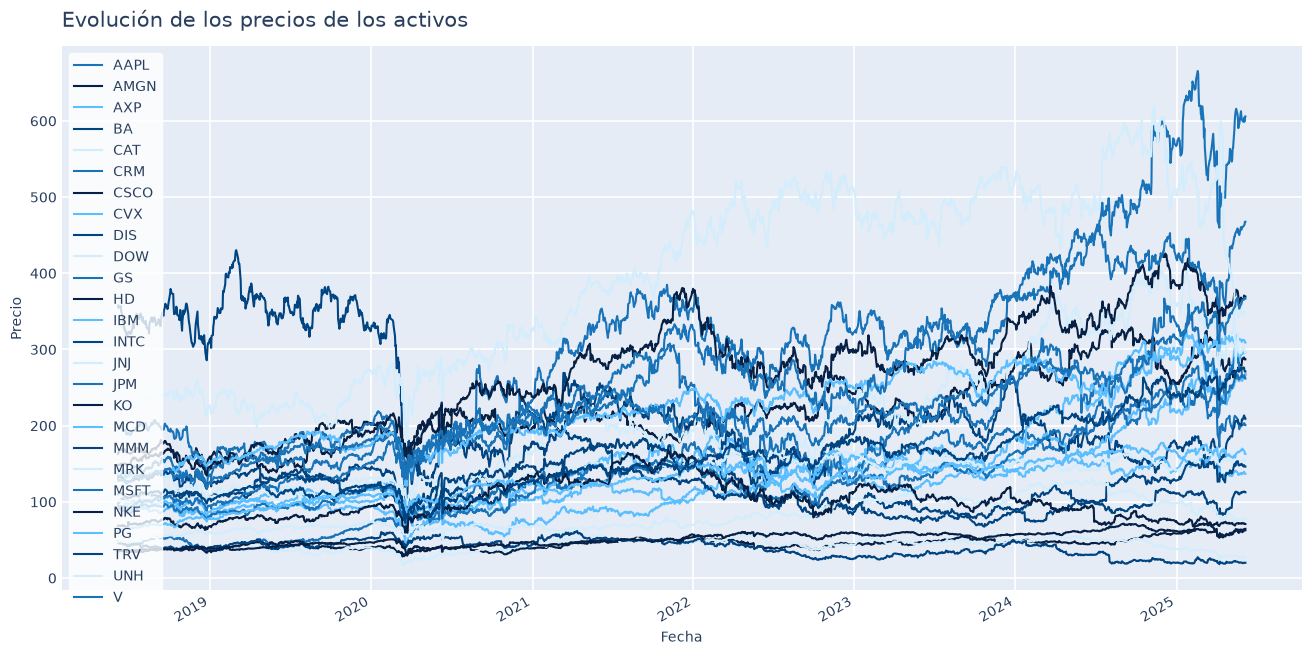

In [17]:
#Representamos los precios de los activos
datos.plot(figsize=(16, 8))

plt.title("Evolución de los precios de los activos")
plt.xlabel("Fecha")
plt.ylabel("Precio")
plt.legend()
plt.show()


### Conclusiones: evolución de los precios

El gráfico de precios absolutos sirve para ver la tendencia general, pero no para comparar los activos entre sí, porque cada uno parte de un nivel muy distinto: al inicio del periodo KO, CSCO o AAPL cotizaban en torno a 45 \$, mientras que GS y UNH superaban los 230 \$ y BA rondaba los 370 \$. La altura de cada línea no indica qué activo se ha comportado mejor; para eso hay que normalizar los precios, como se hace en el apartado 4.

Aun así, se distingue un patrón común a casi todos los activos: tendencia alcista hasta febrero de 2020, una caída brusca y simultánea en marzo de 2020 por la crisis de la COVID-19, recuperación posterior, una corrección en 2022 coincidiendo con la subida de los tipos de interés y una nueva caída en abril de 2025. Que la mayoría de los activos caigan a la vez indica que una parte importante de su riesgo es sistemático, es decir, que procede del mercado en su conjunto y no de cada empresa.

Destaca Boeing (BA), que pasa de más de 400 \$ a principios de 2019 a sus mínimos en 2020 (crisis del 737 MAX y de la COVID-19) y no recupera los niveles anteriores en todo el periodo. También hay que tener en cuenta que DOW solo tiene datos desde el 29 de mayo de 2020, por lo que sus métricas se calculan sobre un periodo más corto. Por último, en junio de 2020 se aprecian saltos verticales en algunas series que no corresponden a movimientos reales del mercado; se analizan en el apartado 5.

## 4. NORMALIZACIÓN DE LOS PRECIOS

Se normalizan los precios a base 100 en el primer día para poder comparar la evolución relativa de activos que parten de precios diferentes.


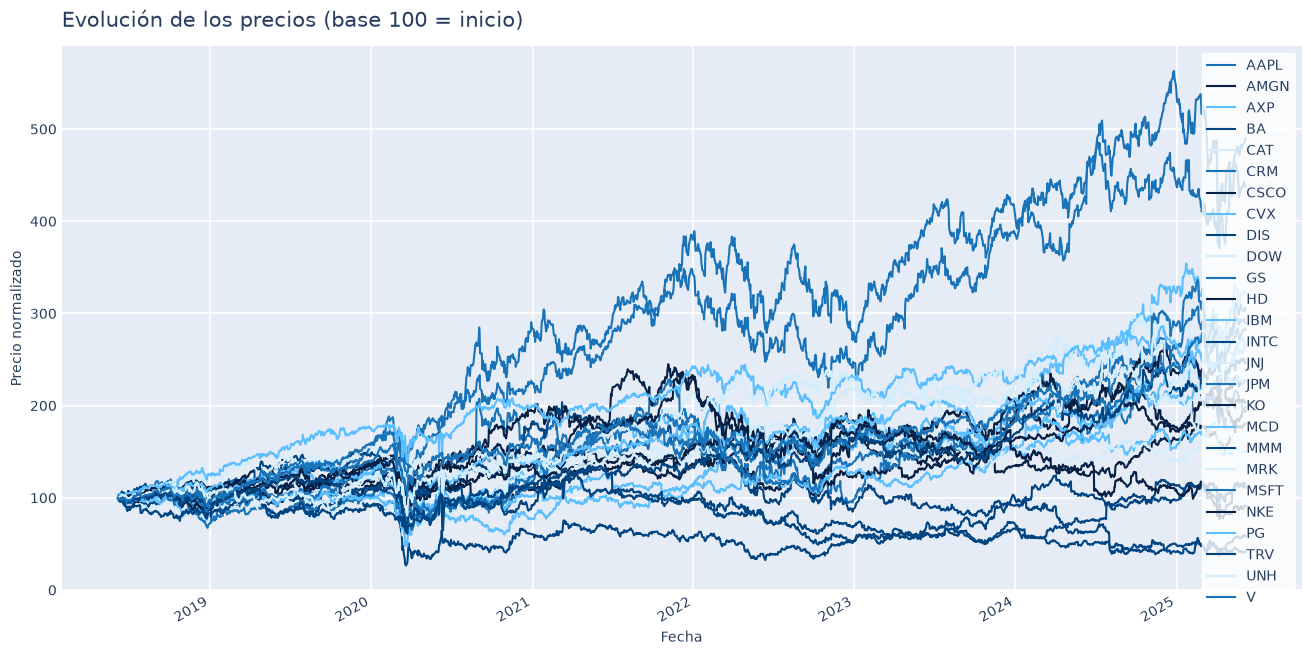

In [18]:
#Normalizamos los precios a base 100
precios_norm = datos / datos.iloc[0] * 100
precios_norm.plot(figsize=(16, 8))

plt.title("Evolución de los precios (base 100 = inicio)")
plt.xlabel("Fecha")
plt.ylabel("Precio normalizado")
plt.legend()
plt.show()

###  Conclusiones: precios normalizados (base 100)

Al normalizar todos los precios a 100 en la primera fecha ya se puede comparar la rentabilidad acumulada. El periodo 2018-2025 ha sido claramente alcista: la mitad de los activos sube más de un 70 % y 11 de los 26 al menos duplican su valor. Microsoft (MSFT) es el activo que más se revaloriza (+384 %), seguido de Apple (AAPL, +315 %), American Express (AXP, +214 %) y Goldman Sachs (GS, +197 %).

En el extremo opuesto, Intel (INTC, −60 %), Boeing (BA, −42 %) y Nike (NKE, −4 %) terminan por debajo de su valor inicial, igual que DOW (−30 % desde su primera cotización en el dataset). En un periodo en el que el mercado sube con fuerza, estos activos han hecho perder dinero al inversor.

Los activos defensivos (KO, PG, JNJ, MCD) siguen una trayectoria más suave que los tecnológicos o los cíclicos, con caídas menores en las crisis, pero también con subidas más moderadas. Además, la distancia entre los activos que más suben y los que menos crece con el tiempo, lo que muestra la importancia de seleccionar bien los activos y de diversificar.

## 5. CÁLCULO DE RENTABILIDADES

Calculamos la rentabilidad diaria mediante el cambio porcentual entre un precio y el anterior.

También se prepara una función para calcular la rentabilidad anualizada siguiendo la estructura utilizada en clase.


In [19]:
# Rentabilidad diaria
rentabilidades = datos.pct_change()
rentabilidades.head()

Ticker,AAPL,AMGN,AXP,BA,CAT,CRM,CSCO,CVX,DIS,DOW,...,KO,MCD,MMM,MRK,MSFT,NKE,PG,TRV,UNH,V
2018-06-06,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018-06-07,-0.002577,-0.001362,0.005051,-0.008155,-0.001406,-0.019476,-0.013782,0.029016,0.005495,NaN,...,-0.000460,0.043725,0.005935,0.000969,-0.015709,0.000134,0.018964,0.013828,0.001327,-0.017904
2018-06-08,-0.010284,0.005456,-0.004730,0.002632,-0.006206,0.004665,-0.003895,-0.004096,0.014736,NaN,...,0.011740,-0.003363,0.007412,0.009518,0.007435,0.001873,0.018743,0.011944,0.006828,0.006725
2018-06-11,-0.001828,0.001682,0.001980,0.003897,0.006470,0.003370,0.004830,0.008858,0.003558,NaN,...,0.004096,-0.014327,-0.007116,-0.003995,-0.005707,-0.004139,0.004535,-0.006244,0.012366,-0.002375
2018-06-12,0.006068,0.002492,-0.004644,-0.000863,0.014745,0.017017,0.005722,-0.003763,-0.000192,NaN,...,0.006345,0.001441,-0.000975,0.001765,0.002573,-0.002413,-0.003740,-0.007050,-0.000788,0.002083


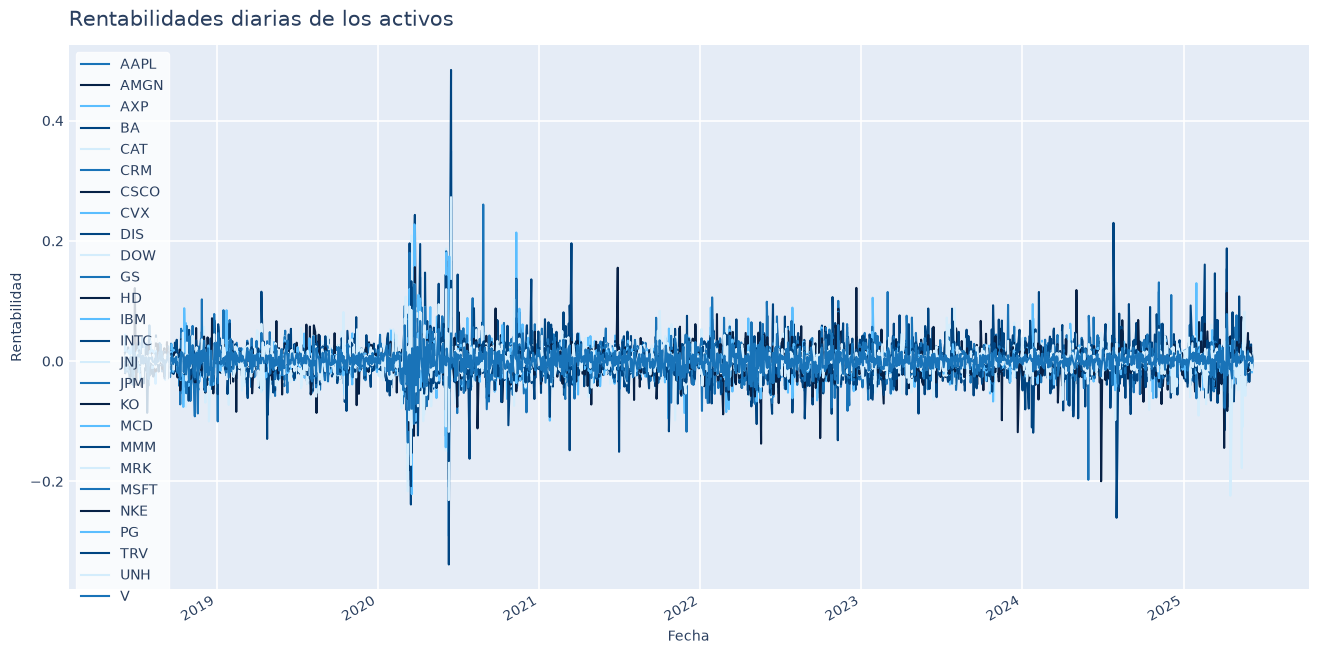

In [20]:
# Representamos las rentabilidades diarias
rentabilidades.plot(figsize=(16, 8))

plt.title("Rentabilidades diarias de los activos")
plt.xlabel("Fecha")
plt.ylabel("Rentabilidad")
plt.legend()
plt.show()

###  Conclusiones: rentabilidades diarias

Las rentabilidades diarias oscilan alrededor de cero, como es habitual en las series financieras, y la mayor parte del tiempo se mantienen en un rango estrecho. Sin embargo, se observa claramente el agrupamiento de la volatilidad (*volatility clustering*): los movimientos grandes se concentran en determinados periodos. En marzo de 2020, 22 de los 26 activos tuvieron al menos una sesión con una variación superior al 10 %; por ejemplo, MSFT subió un 14,2 % el 13 de marzo y cayó un 14,7 % el día 16. Fuera de las crisis, los movimientos extremos son puntuales y se deben a noticias de cada empresa, como la caída de Intel del 26 % el 2 de agosto de 2024 o la de UnitedHealth del 22 % el 17 de abril de 2025, ambas tras publicar resultados.

Hay que señalar un problema de calidad de los datos en junio de 2020: 16 activos registran variaciones superiores al 10 % que se deshacen pocos días después y que son muy superiores a las del mercado en esas fechas. Los casos más claros son MMM (+53,8 % el 3 de junio, −33,8 % el día 10 y +48,4 % el día 15), DOW (−26,5 % y +39,6 % en dos sesiones consecutivas) y KO (−16,4 % y +15,7 % en la misma semana). Como se comprueba en el apartado 16.4, no coinciden con ningún split, así que lo más probable es que sean errores del dataset. Estos datos inflan la volatilidad y el drawdown de los activos afectados, sobre todo de MMM, MRK, IBM y DOW (y, en menor medida, de otros como CAT, HD o JPM), y hay que tenerlo en cuenta al interpretar sus métricas.

In [21]:
# Función para calcular rentabilidades anualizadas
def rtb_anualizada(tipo, n, p0, p1, dias_habiles):

    if tipo == 'd':
        r = (p1 - p0) / p0
        return ((1 + r) ** (dias_habiles / n)) - 1

    if tipo == 'm':
        r = (p1 - p0) / p0
        return ((1 + r) ** (12 / n)) - 1

    if tipo == 'y':
        r = (p1 - p0) / p0
        return ((1 + r) ** (1 / n)) - 1

    else:
        print("Por favor, introduzca 'd', 'm' o 'y' en el tipo")
        return

In [22]:
# Calculamos las principales rentabilidades de cada activo
def calcular_rentabilidades(precios, dias_habiles=252):
    resultados = []

    for activo in precios.columns:

        serie = precios[activo].dropna()
        rent_diarias = serie.pct_change().dropna()
        rent_media = rent_diarias.mean()
        rent_activa = (serie.iloc[-1] - serie.iloc[0]) / serie.iloc[0]
        n = len(serie)
        rent_anual = rtb_anualizada('d', n, serie.iloc[0], serie.iloc[-1], dias_habiles)
        resultados.append([activo, rent_media, rent_activa, rent_anual])

    return pd.DataFrame(resultados, columns=["Activo", "Rentabilidad media diaria", "Rentabilidad acumulada", "Rentabilidad anualizada"]).set_index("Activo")

In [23]:
# Tabla de rentabilidades
tabla_rentabilidades = calcular_rentabilidades(datos)
tabla_rentabilidades.style.format("{:.2%}")

,Rentabilidad media diaria,Rentabilidad acumulada,Rentabilidad anualizada
Activo,,,
AAPL,0.10%,337.19%,23.50%
AMGN,0.05%,93.59%,9.91%
AXP,0.09%,222.70%,18.25%
BA,0.01%,-41.55%,-7.40%
CAT,0.08%,161.30%,14.73%
CRM,0.07%,98.49%,10.31%
CSCO,0.05%,80.41%,8.81%
CVX,0.04%,50.46%,6.02%
DIS,0.03%,14.95%,2.01%


## 6. CÁLCULO DE LA VOLATILIDAD

Calculamos la desviación típica diaria y la volatilidad anualizada.

La anualización se realiza utilizando 252 días de cotización, siguiendo el procedimiento utilizado en clase.


In [24]:
# Función para calcular la volatilidad anualizada
def volatilidad_anualizada(precios, dias_habiles=252):
    rentabilidades = precios.pct_change().dropna()
    desviacion = rentabilidades.std(ddof=0)
    return desviacion * np.sqrt(dias_habiles)

In [25]:
# Calculamos la volatilidad de todos los activos
volatilidades = {}
for activo in datos.columns:
    volatilidades[activo] = volatilidad_anualizada(datos[activo])

tabla_volatilidad = pd.DataFrame.from_dict(volatilidades, orient="index", columns=["Volatilidad anualizada"])
tabla_volatilidad.style.format("{:.2%}")

,Volatilidad anualizada
AAPL,31.67%
AMGN,25.34%
AXP,34.30%
BA,46.51%
CAT,33.04%
CRM,37.81%
CSCO,28.04%
CVX,32.51%
DIS,31.94%
DOW,36.63%


## 7. VOLATILIDAD EN VENTANAS TEMPORALES

Calculamos la secuencia de volatilidades utilizando una ventana móvil.

Se utiliza una ventana de 30 días, como en el ejercicio de referencia de clase.


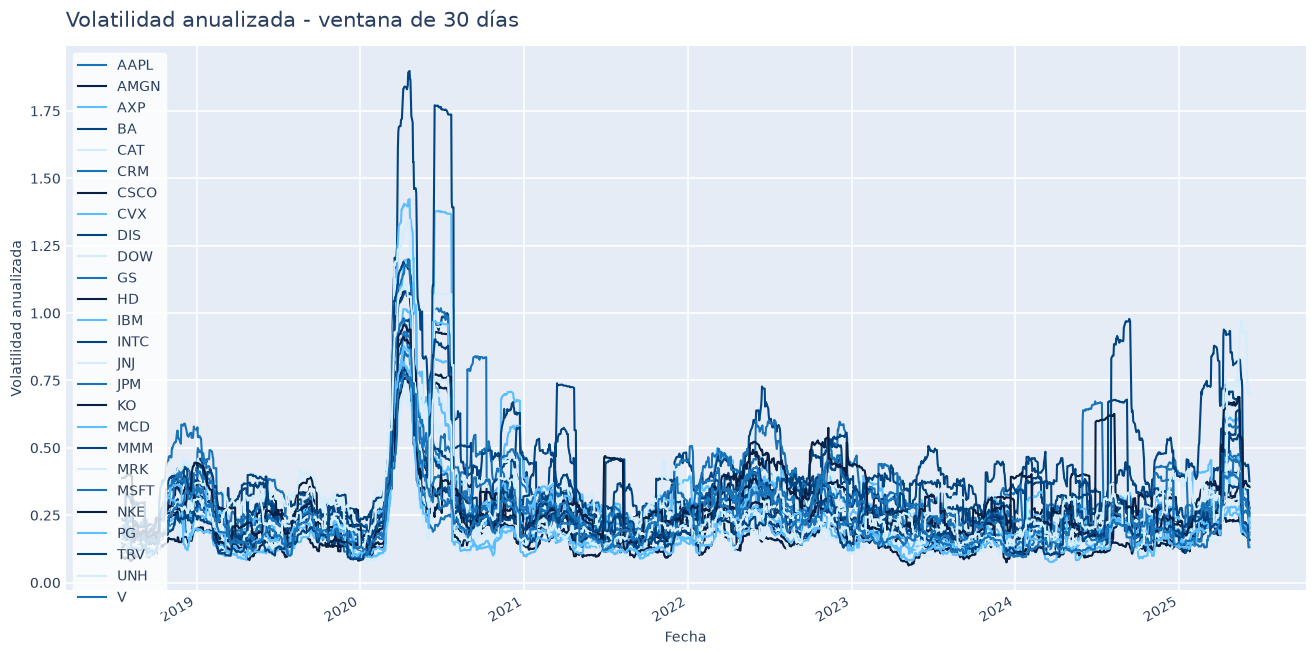

In [26]:
# Volatilidad anualizada a 30 días
volatilidad_30 = rentabilidades.rolling(30).std(ddof=0) * np.sqrt(252)
volatilidad_30.plot(figsize=(16, 8))

plt.title("Volatilidad anualizada - ventana de 30 días")
plt.xlabel("Fecha")
plt.ylabel("Volatilidad anualizada")
plt.legend()
plt.show()

###  Conclusiones: volatilidad anualizada a 30 días

La volatilidad no es constante en el tiempo. En condiciones normales, la volatilidad anualizada a 30 días de la mayoría de los activos se mueve entre el 15 % y el 35 % (su mediana va del 14 % de KO al 36 % de INTC), pero en marzo y abril de 2020 se dispara: la volatilidad media de los 26 activos llega casi al 100 % a principios de abril, y BA alcanza el 190 %. Es un episodio de crisis sistémica en el que todos los activos se vuelven más arriesgados a la vez.

Después de 2020 la volatilidad vuelve a sus niveles habituales, aunque con repuntes en 2022 (subida de tipos e inflación) y, sobre todo, en abril y mayo de 2025, cuando la volatilidad media de los activos llega al 50 %. Que tras cada pico vuelva a su nivel normal es lo que se conoce como reversión a la media de la volatilidad.

Algunos picos no corresponden a movimientos reales: los máximos de MMM (240 %), MRK (150 %), DOW (143 %) o IBM (127 %) se producen en junio y julio de 2020 y se deben a los datos erróneos comentados en el apartado anterior, que la ventana de 30 días arrastra durante un mes.

La conclusión financiera es que una única volatilidad histórica para todo el periodo infravalora el riesgo en las crisis y lo sobrevalora en los periodos de calma, por lo que es preferible medir el riesgo en ventanas temporales.

## 8. RATIO DE SHARPE

El ratio de Sharpe se calcula como:

$S_h = \frac{r-r_f}{\sigma}$

Para el cálculo se utilizará la rentabilidad anualizada y la volatilidad anualizada.


In [27]:
# Tipo de interés libre de riesgo
rf = 0.0

# Función para calcular el ratio de Sharpe
def ratio_sharpe(precios, rf=0.0, dias_habiles=252):

    serie = precios.dropna()
    rent_anual = rtb_anualizada('d', len(serie), serie.iloc[0], serie.iloc[-1], dias_habiles)
    vol_anual = volatilidad_anualizada(serie, dias_habiles)
    return (rent_anual - rf) / vol_anual

In [28]:
# Calculamos el ratio de Sharpe para todos los activos
sharpe = {}

for activo in datos.columns:
    sharpe[activo] = ratio_sharpe(datos[activo], rf)

tabla_sharpe = pd.DataFrame.from_dict(sharpe, orient="index", columns=["Sharpe"])
tabla_sharpe

,Sharpe
AAPL,0.742263
AMGN,0.391209
AXP,0.532102
BA,-0.159027
CAT,0.445985
CRM,0.272600
CSCO,0.314170
CVX,0.185196
DIS,0.063028
DOW,-0.095393


## 9. RATIO DE SORTINO

El ratio de Sortino es similar al Sharpe, pero utiliza únicamente la volatilidad asociada a rentabilidades negativas.

Se prepara como métrica adicional de riesgo para completar el análisis solicitado.


In [29]:
# Función para calcular el ratio de Sortino
def ratio_sortino(precios, rf=0.0, dias_habiles=252):
    serie = precios.dropna()
    rent_diarias = serie.pct_change().dropna()
    rent_anual = rtb_anualizada('d', len(serie), serie.iloc[0], serie.iloc[-1], dias_habiles)
    rent_rf_diaria = (1 + rf) ** (1 / dias_habiles) - 1
    rent_negativas = rent_diarias[rent_diarias < rent_rf_diaria]
    downside = np.sqrt(((rent_negativas - rent_rf_diaria) ** 2).mean()) * np.sqrt(dias_habiles)

    return (rent_anual - rf) / downside

In [30]:
# Calculamos el ratio de Sortino
sortino = {}

for activo in datos.columns:
    sortino[activo] = ratio_sortino(datos[activo], rf)

tabla_sortino = pd.DataFrame.from_dict(sortino, orient="index", columns=["Sortino"])
tabla_sortino

,Sortino
AAPL,0.738240
AMGN,0.410812
AXP,0.550134
BA,-0.164849
CAT,0.444181
CRM,0.273300
CSCO,0.298383
CVX,0.178553
DIS,0.065665
DOW,-0.094093


## 10. DRAWDOWN MÁXIMO

El drawdown mide la caída de un activo desde un máximo anterior.

$Drawdown_i = \frac{p_i}{p_{max}} - 1$

Calculamos también el máximo drawdown dentro de una ventana temporal de 252 días.


In [31]:
# Función para calcular el drawdown
def drawdown(precios, ventana=252, plot=0):

    precios = precios.dropna()
    roll_max = precios.rolling(window=ventana, min_periods=1).max()
    daily_draw_down = precios / roll_max - 1

    max_daily_draw_down = daily_draw_down.rolling(window=ventana, min_periods=1).min()
    if plot == 1:
        fig, ax = plt.subplots(figsize=(16, 8))
        ax.plot(daily_draw_down.index, daily_draw_down, label="Daily drawdown", color=paleta_bbva["azul_logotipo"])
        ax.plot(max_daily_draw_down.index, max_daily_draw_down, label="Maximum drawdown in time window", color=paleta_bbva["azul_celeste_aqua"])
        ax.legend()
        plt.show()

    return daily_draw_down, max_daily_draw_down

In [32]:
# Calculamos el drawdown máximo de cada activo
drawdowns_maximos = {}

for activo in datos.columns:
    daily_draw_down, max_daily_draw_down = drawdown(datos[activo], ventana=252)
    drawdowns_maximos[activo] = max_daily_draw_down.min()

tabla_drawdown = pd.DataFrame.from_dict(drawdowns_maximos, orient="index", columns=["Drawdown máximo"])
tabla_drawdown.style.format("{:.2%}")

,Drawdown máximo
AAPL,-38.57%
AMGN,-24.86%
AXP,-49.64%
BA,-75.42%
CAT,-40.34%
CRM,-54.91%
CSCO,-41.95%
CVX,-55.77%
DIS,-50.60%
DOW,-60.87%


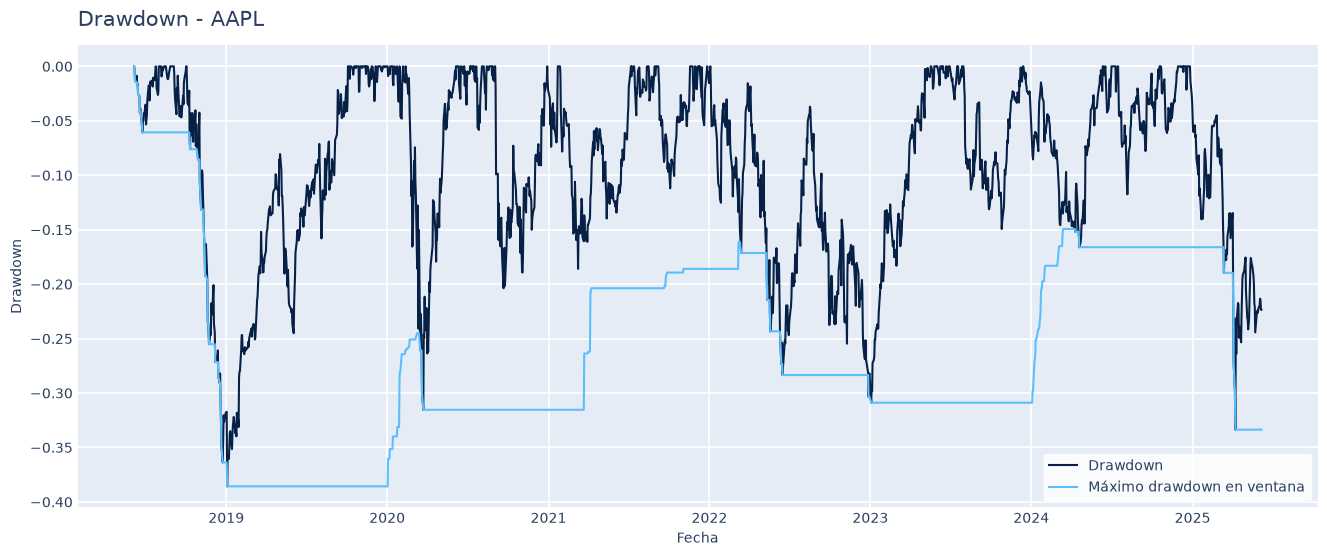

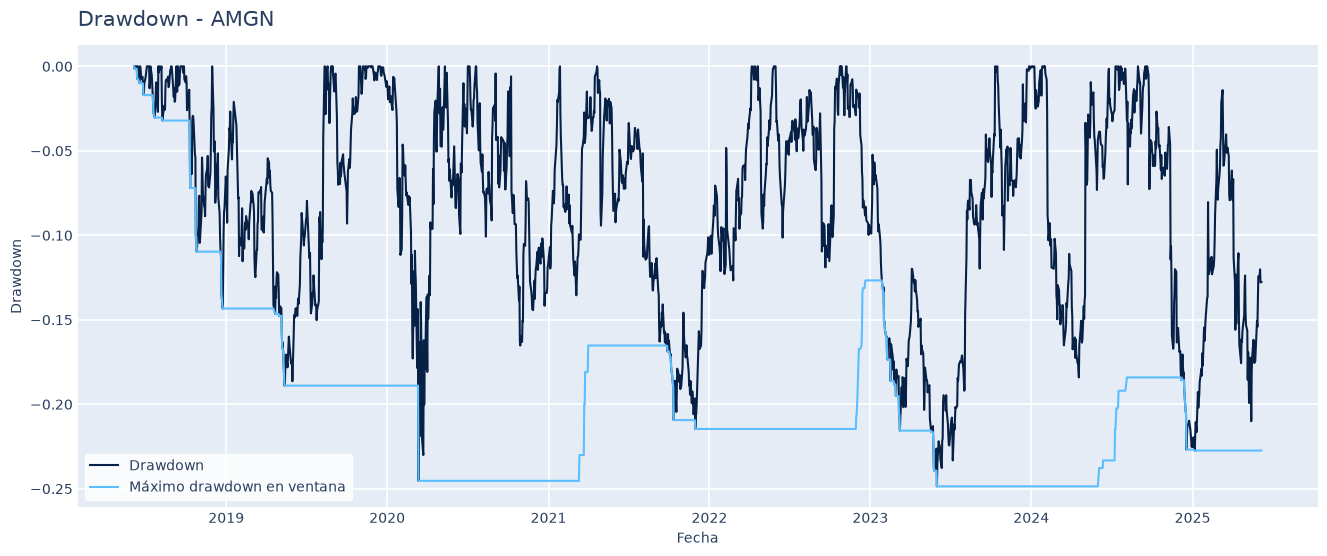

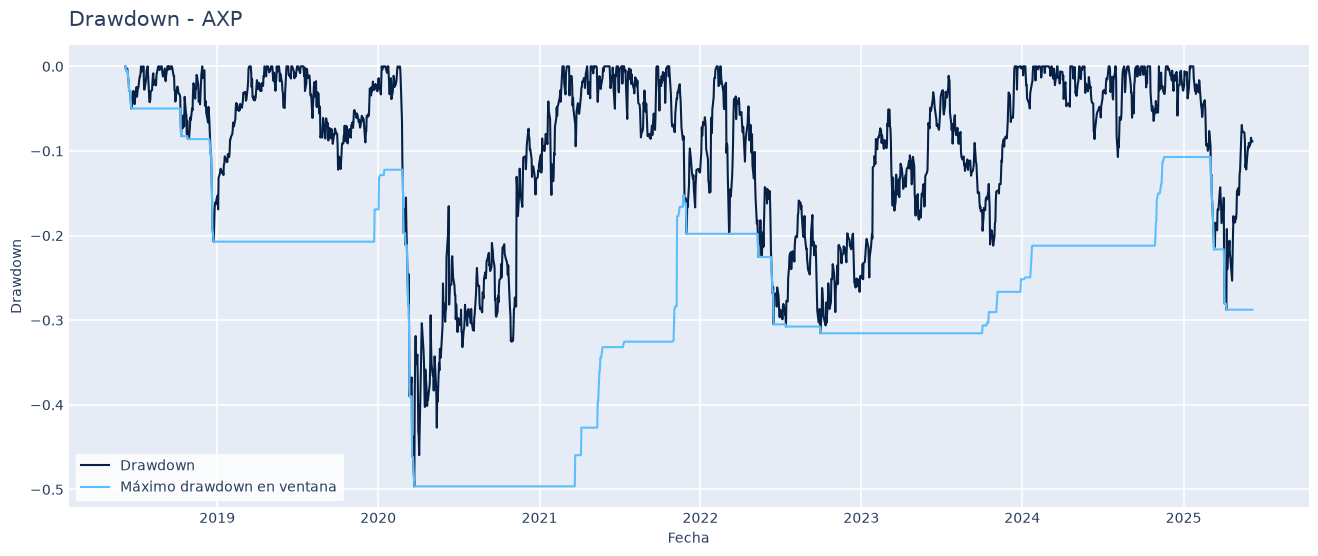

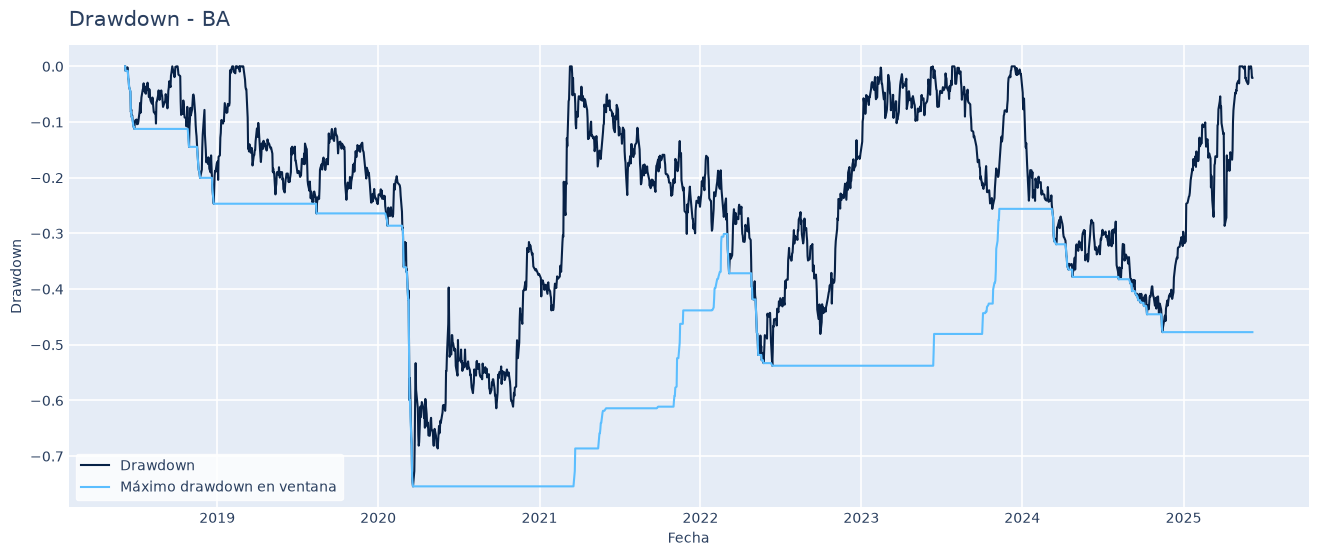

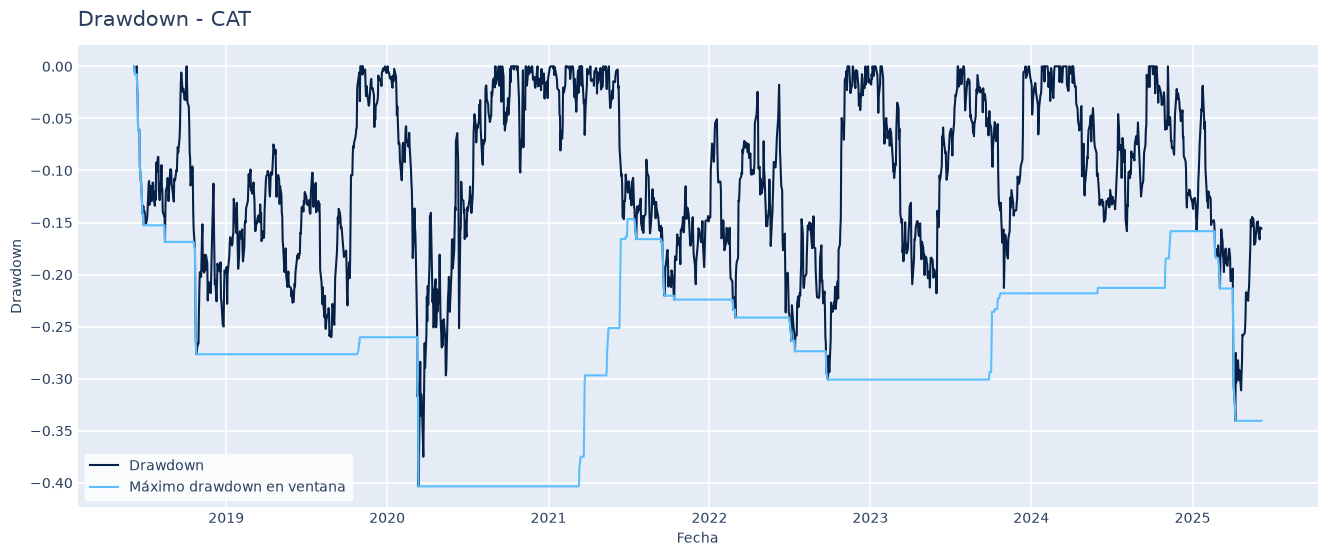

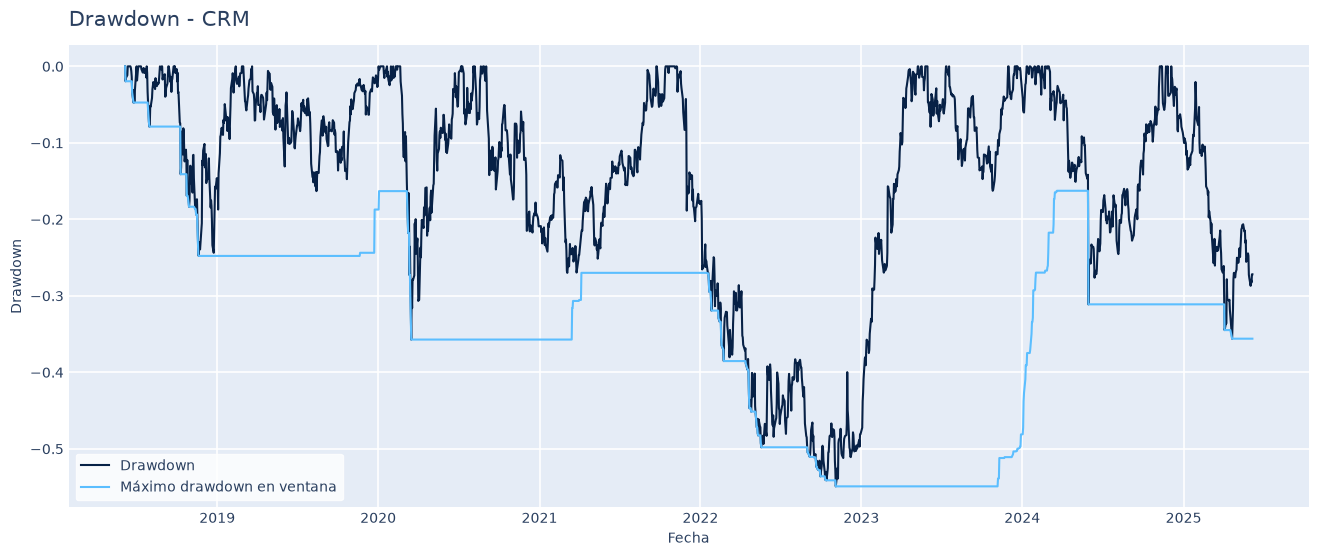

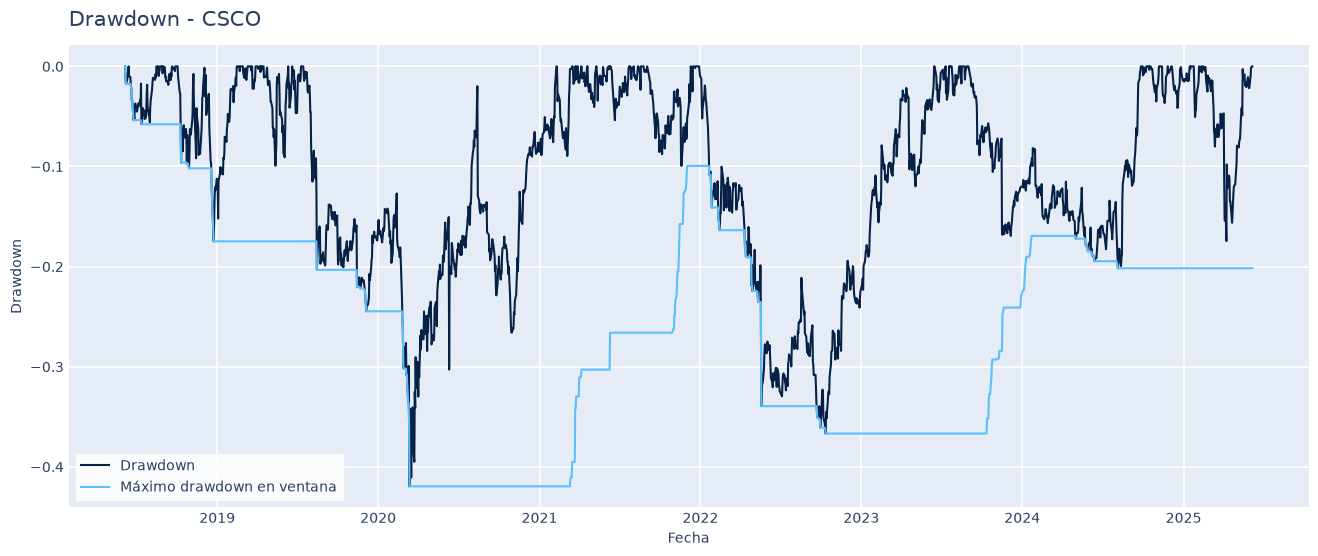

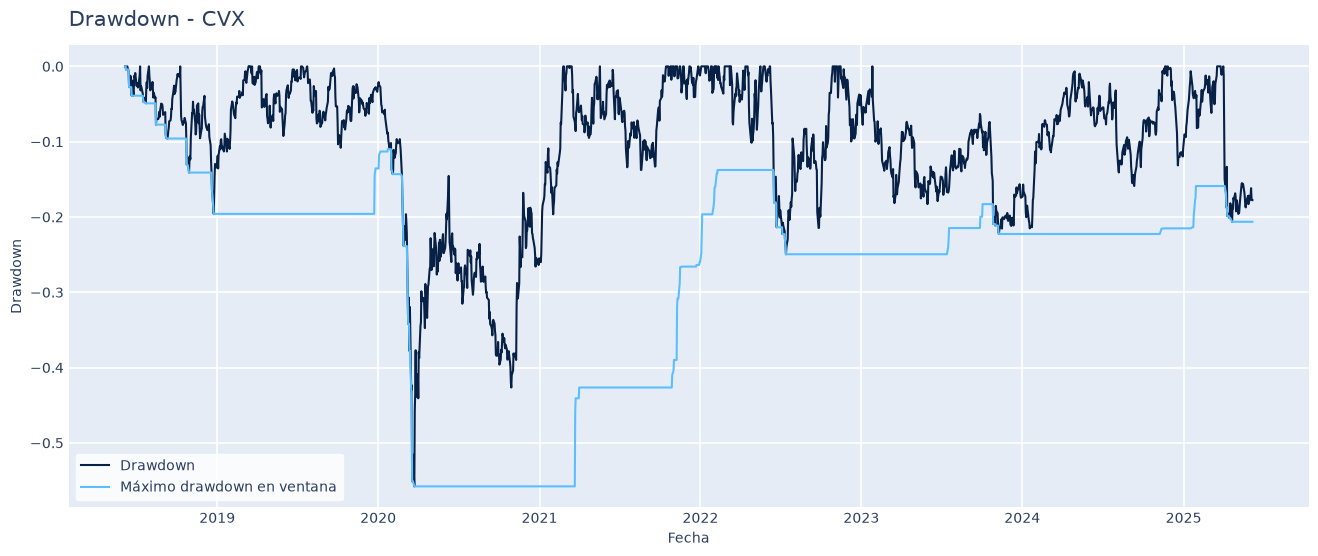

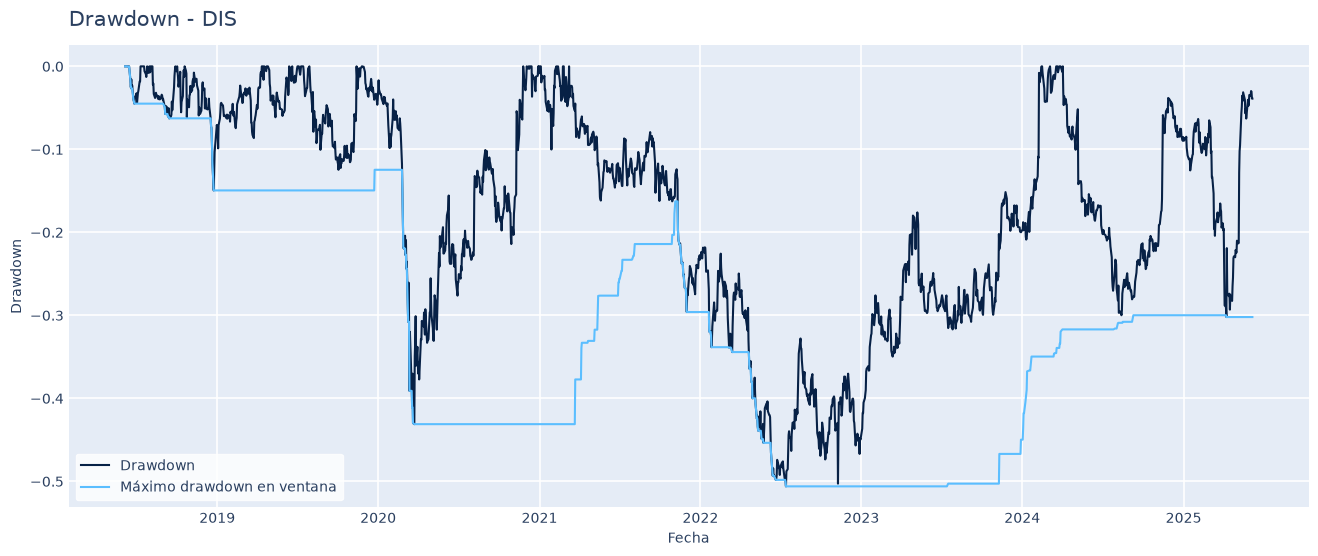

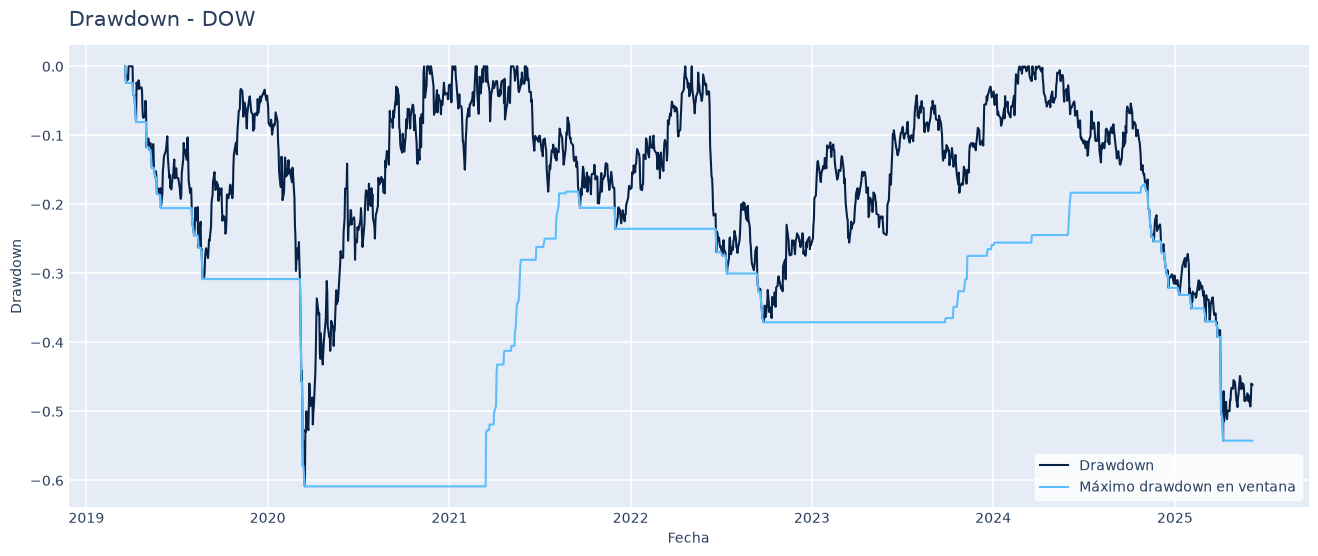

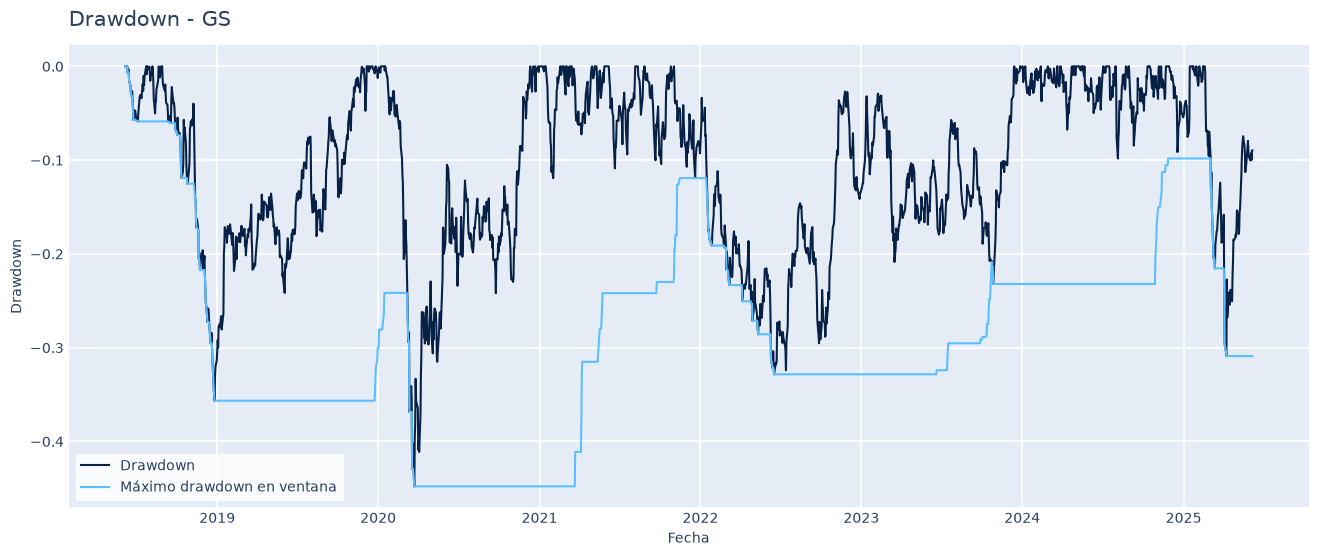

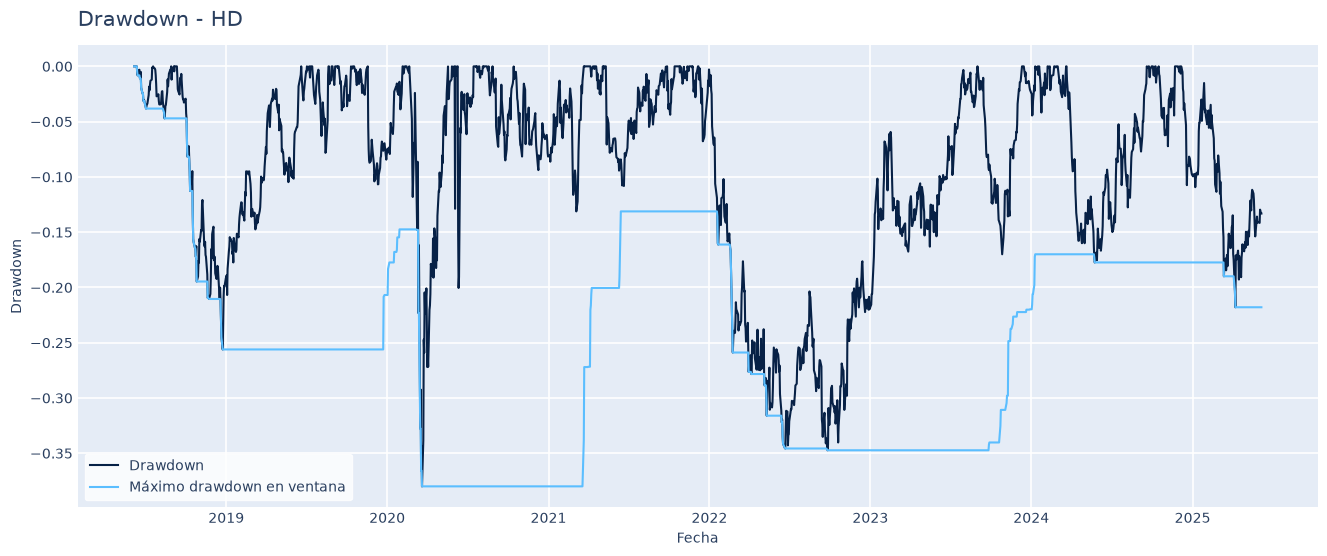

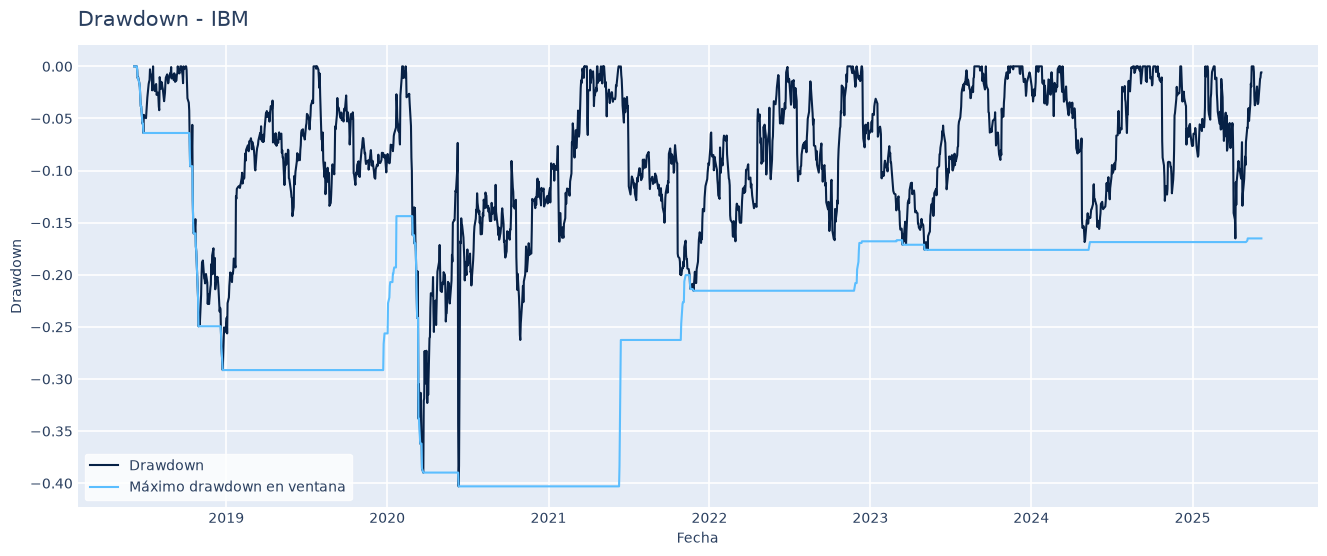

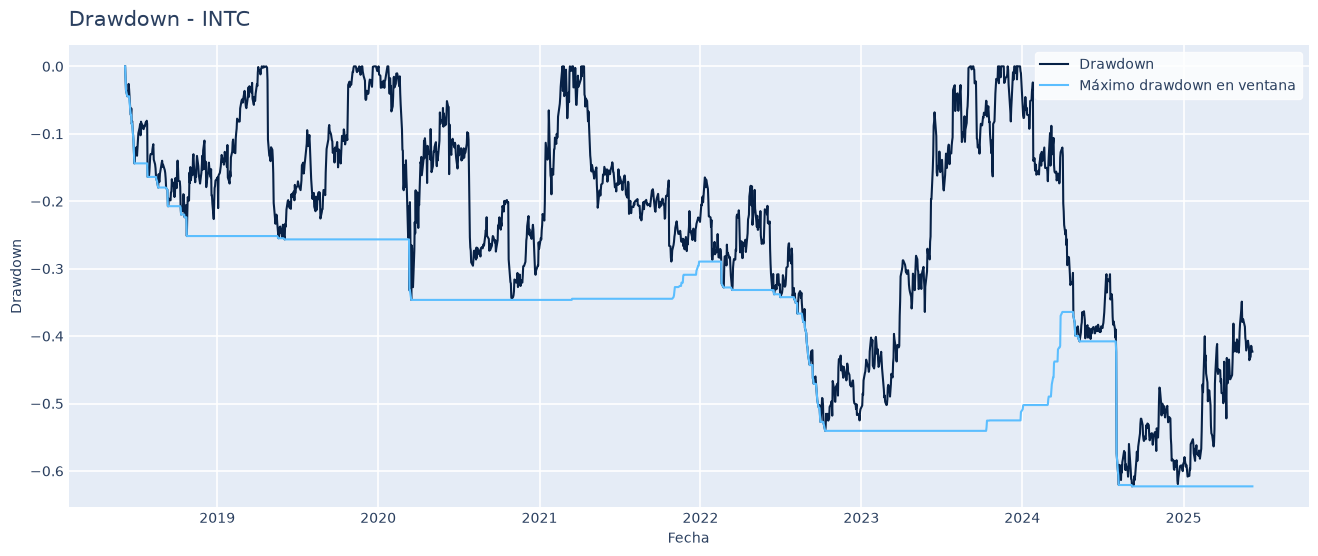

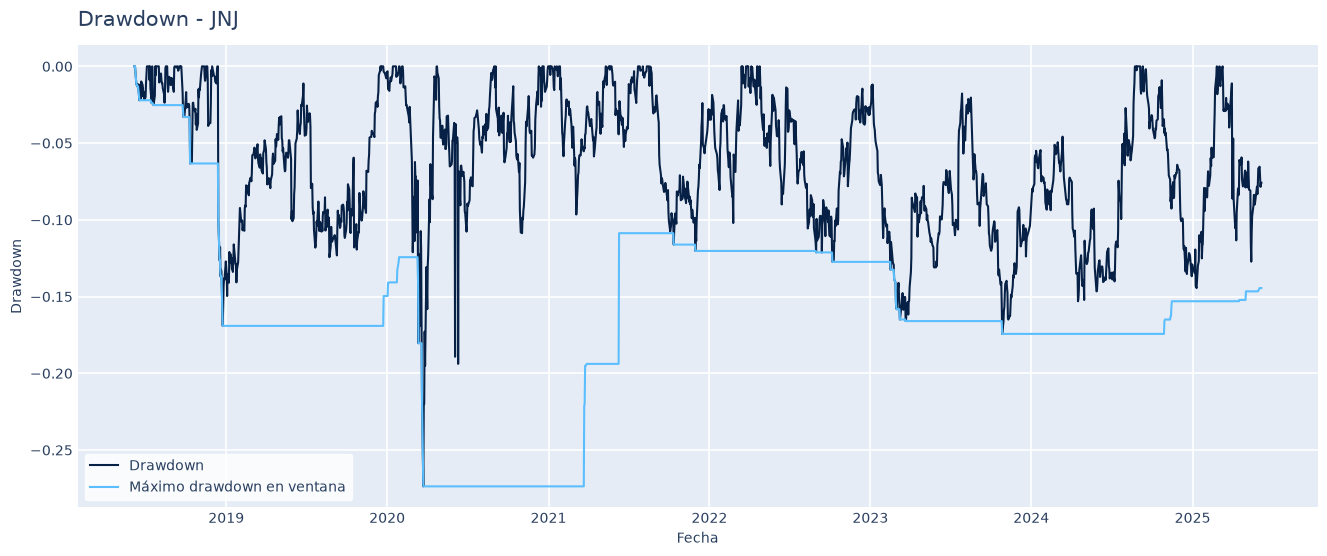

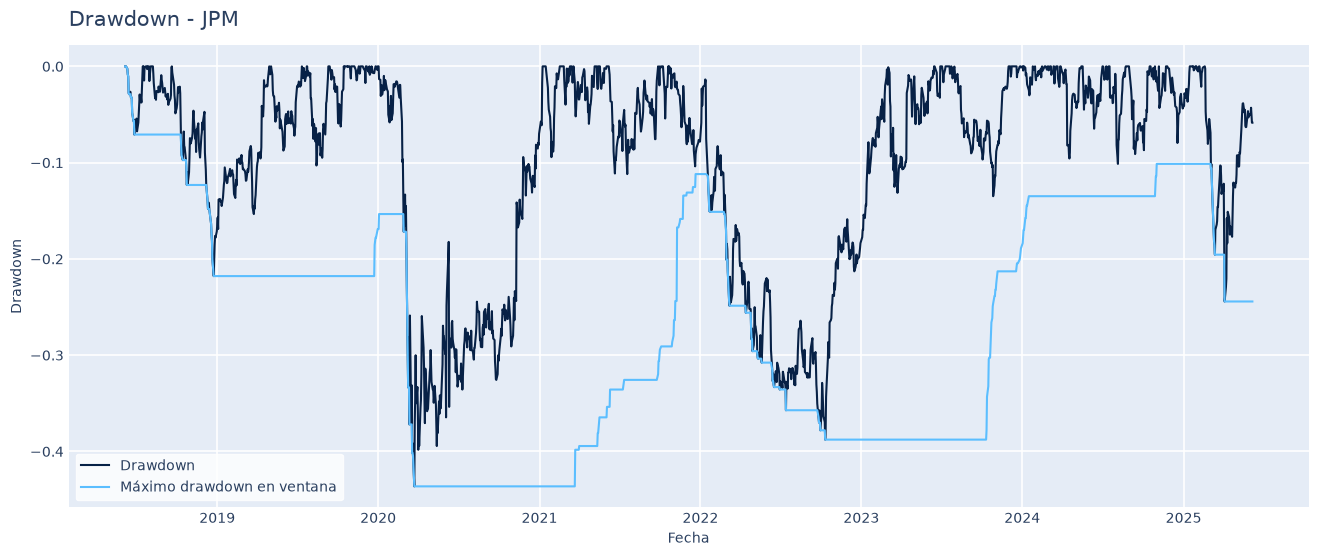

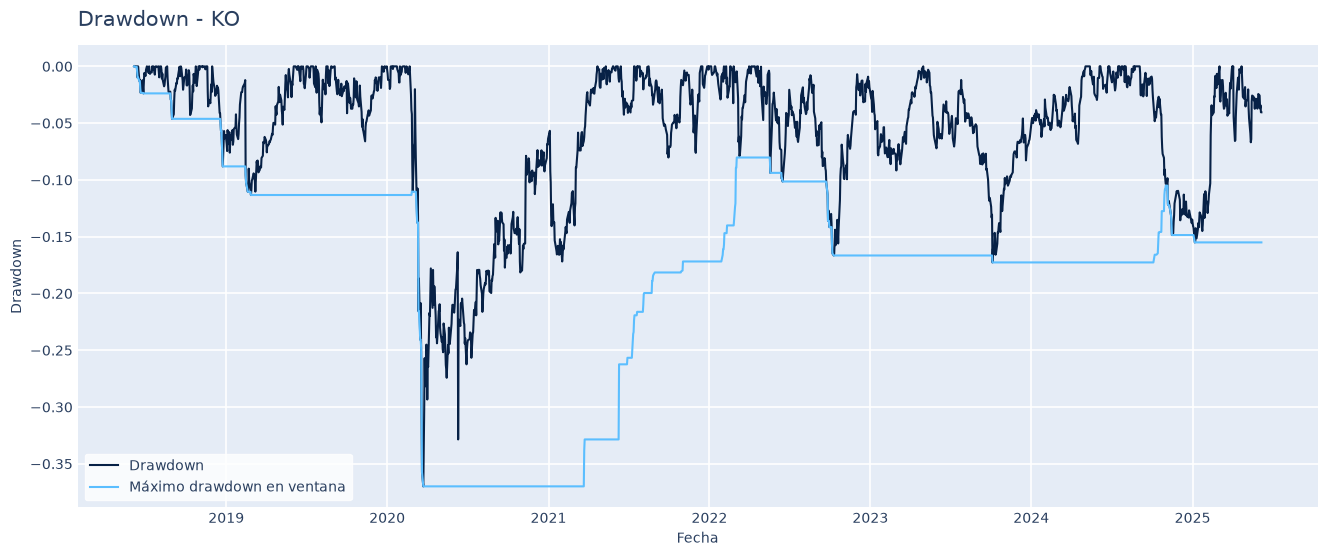

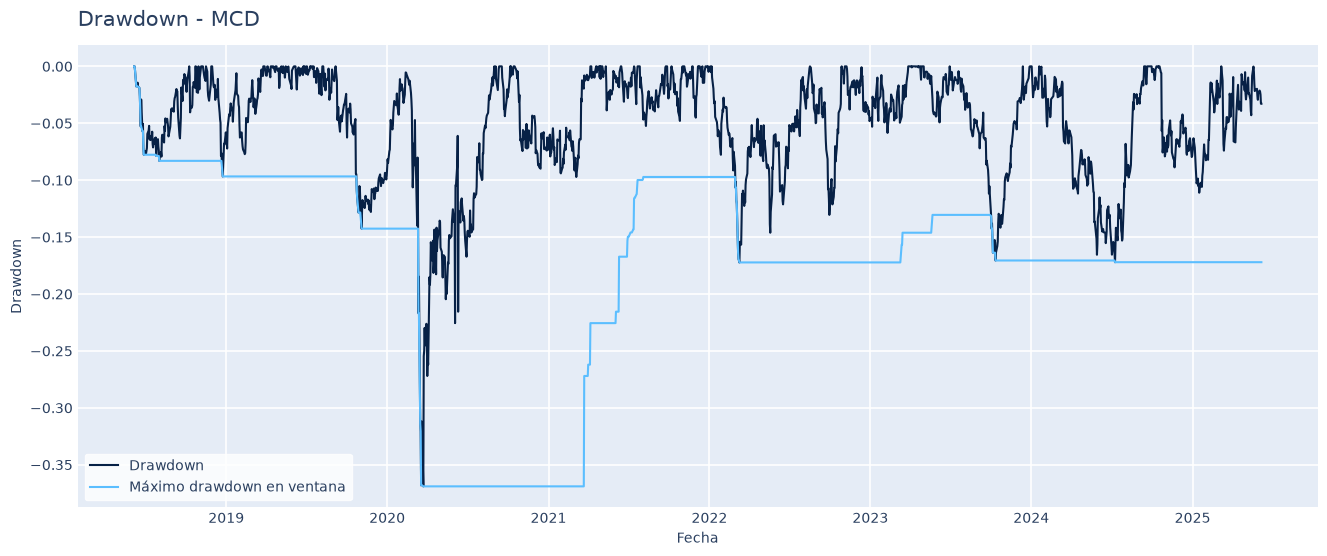

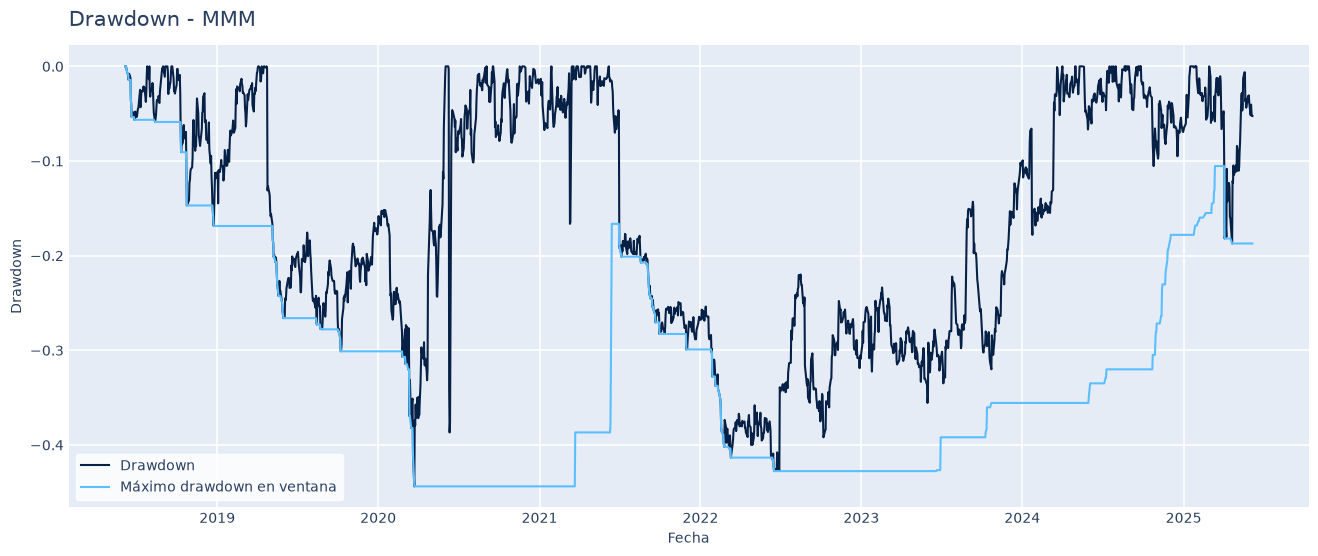

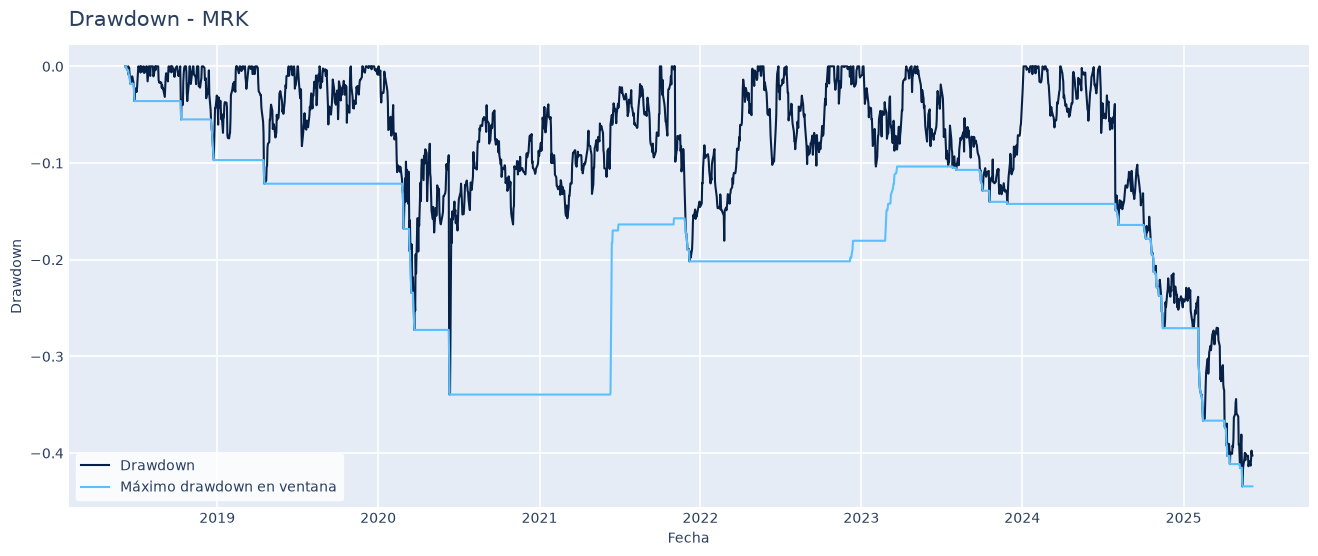

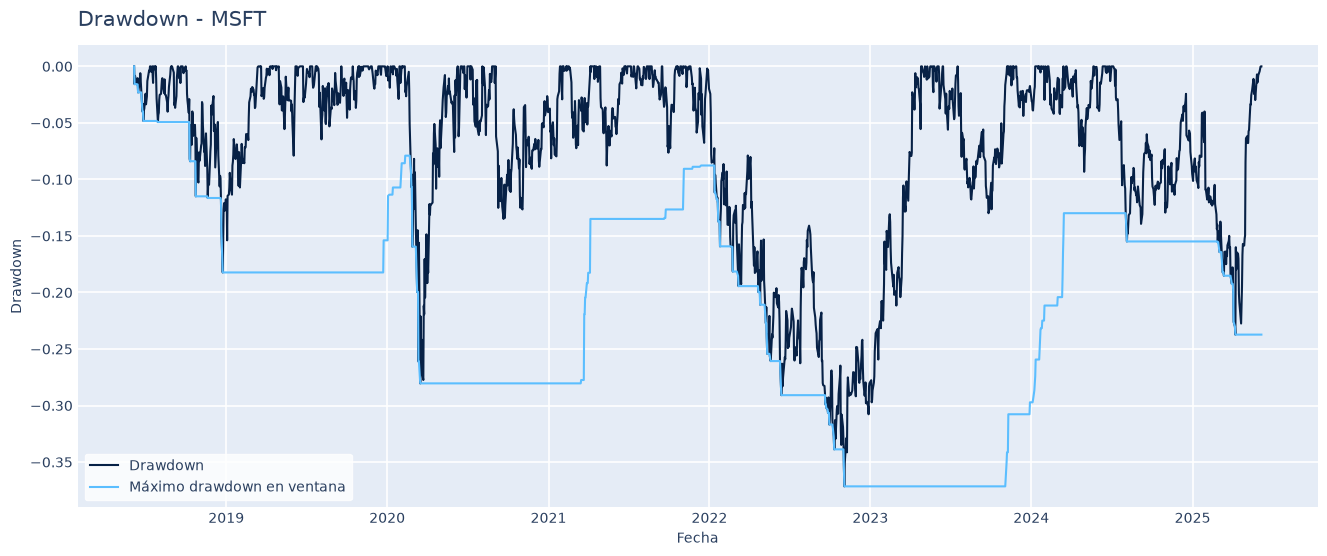

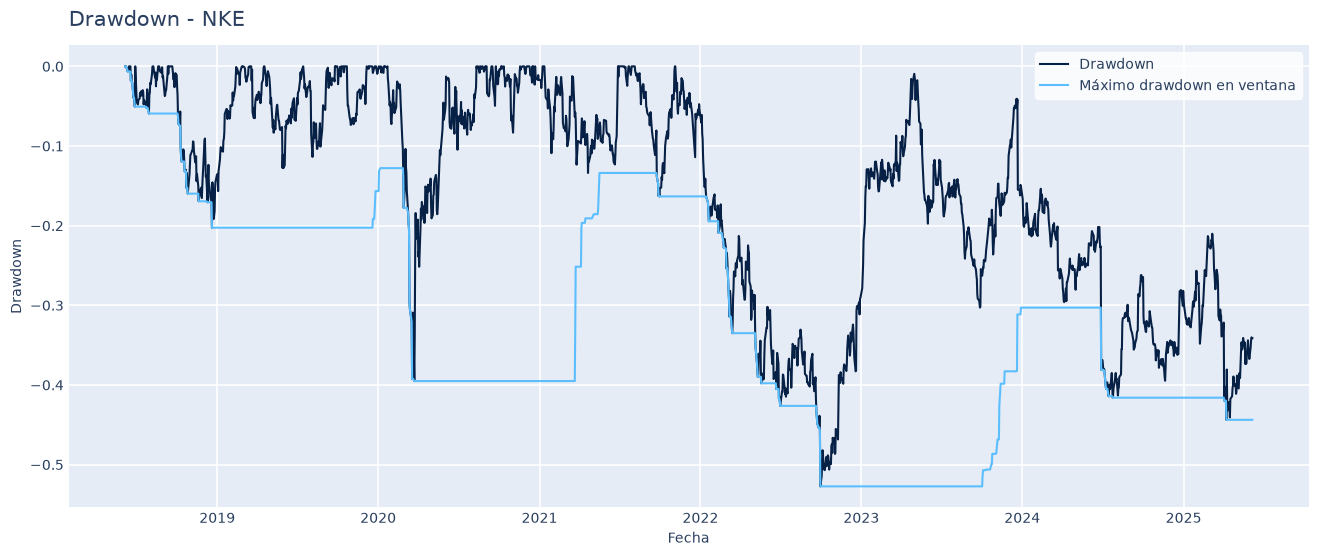

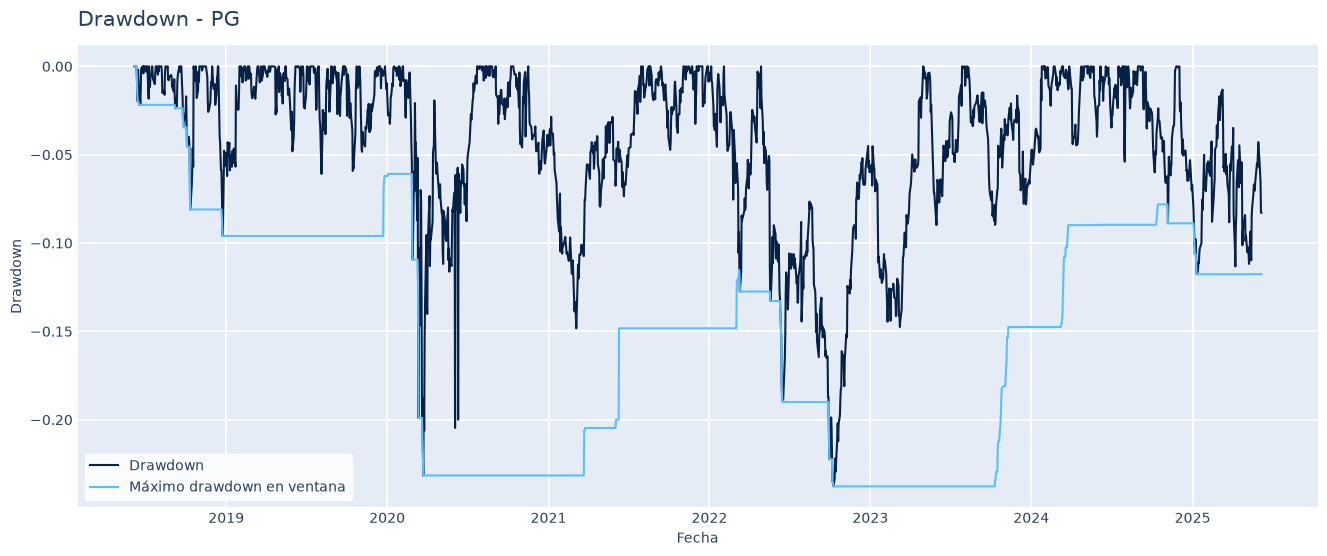

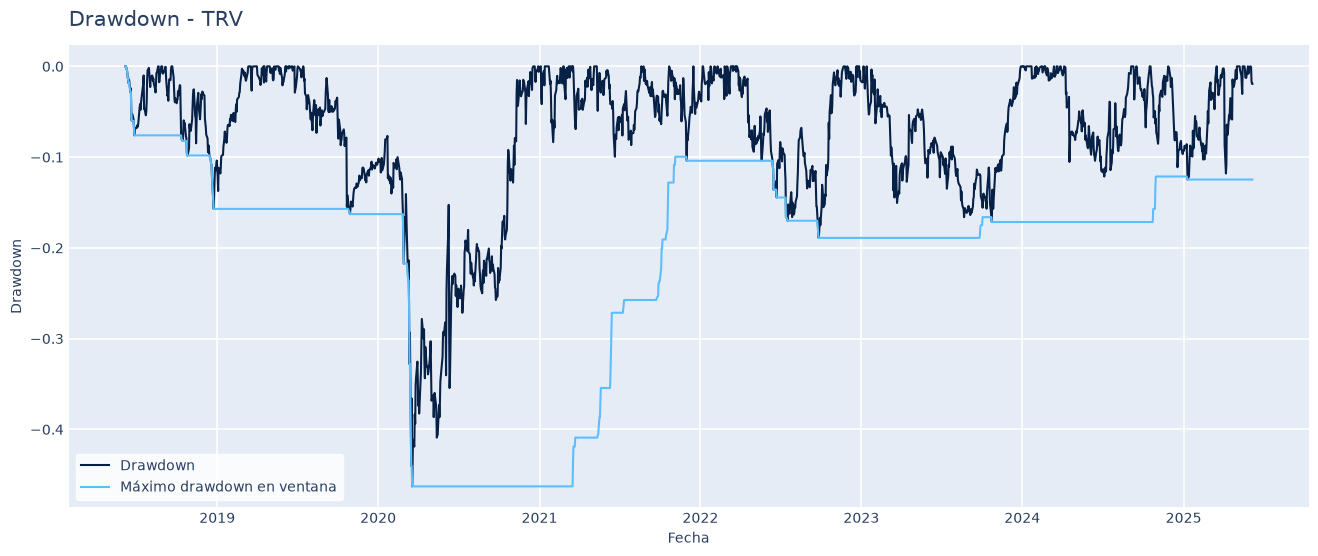

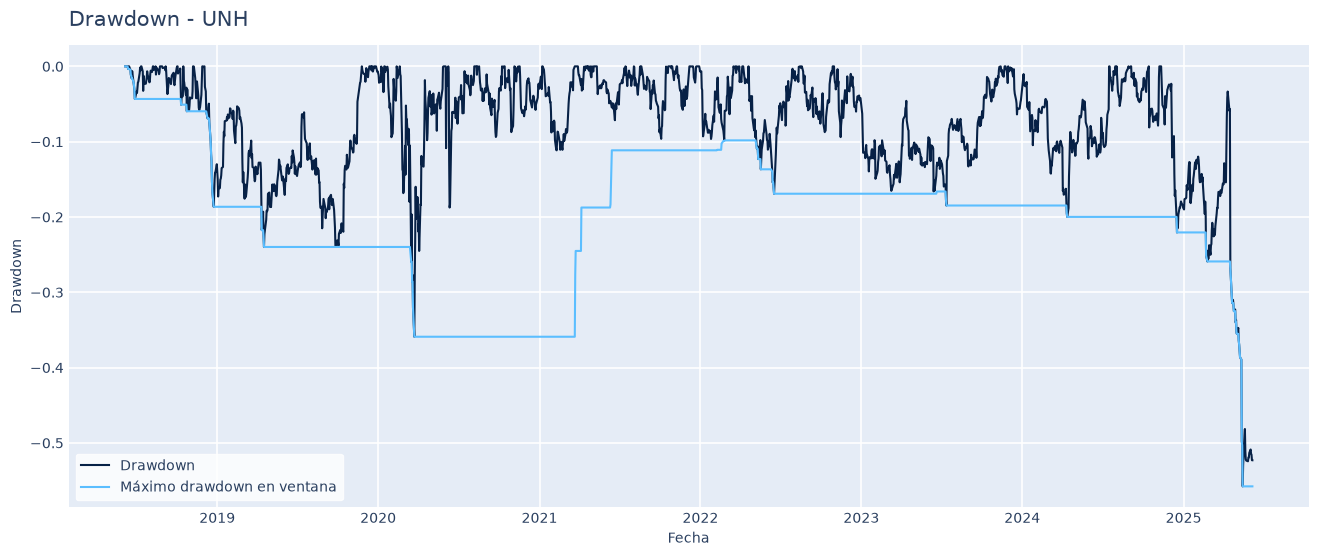

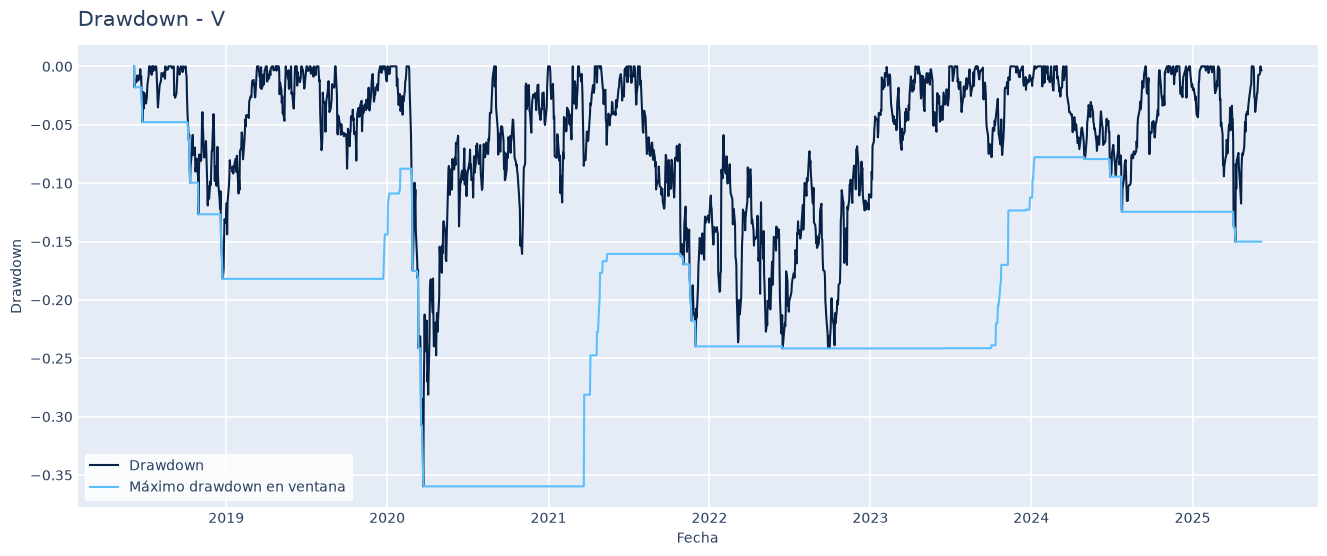

In [33]:
# Ejemplo de representación del drawdown de todos los activos
for activo in datos.columns:
    daily_draw_down, max_daily_draw_down = drawdown(datos[activo], ventana=252)

    plt.figure(figsize=(16, 6))
    plt.plot(daily_draw_down.index, daily_draw_down, label="Drawdown", color=paleta_bbva["azul_oscuro_digital"])
    plt.plot(max_daily_draw_down.index, max_daily_draw_down, label="Máximo drawdown en ventana", color=paleta_bbva["azul_celeste_aqua"])

    plt.title("Drawdown - " + str(activo))
    plt.xlabel("Fecha")
    plt.ylabel("Drawdown")
    plt.legend()
    plt.show()

###  Conclusiones: drawdown (tabla y gráficos por activo)

El drawdown mide cuánto cae un activo desde su máximo anterior y refleja mejor que la volatilidad lo que puede llegar a perder un inversor en el peor momento. Los mayores drawdowns corresponden a BA (−76 %), INTC (−63 %), CVX (−57 %), DOW (−57 %), UNH (−56 %) y CRM (−55 %). Boeing sufre su peor caída en marzo de 2020 y no llega a recuperarse; en Intel, Nike y DOW, en cambio, el punto más bajo se alcanza en abril de 2025, tras años de caídas progresivas, lo que apunta a problemas propios de cada empresa más que a una crisis puntual.

Los activos defensivos tienen las caídas más contenidas: PG (−25 %), AMGN (−27 %) y JNJ (−28 %), algo coherente con negocios estables y poco dependientes del ciclo económico. Entre los activos más rentables, V (−36 %) y MSFT (−38 %) también limitan bien sus caídas. El peor momento de Microsoft no fue la crisis de 2020, sino noviembre de 2022, con la corrección de las tecnológicas por la subida de tipos.

En los gráficos por activo se ve que marzo de 2020 es el punto de máximo drawdown común a muchos activos. Hay que tener en cuenta que el cálculo usa una ventana de 252 días, así que olvida las caídas de hace más de un año y refleja el riesgo reciente, no el histórico. Por eso, en activos con caídas muy prolongadas, como INTC, la caída total desde el máximo del periodo es mayor que la de la tabla (−74 %).

En conclusión, dos activos con una volatilidad parecida pueden tener drawdowns muy distintos, por lo que ambas métricas se complementan.

## 11. TABLA FINAL DE RENTABILIDAD Y RIESGO

Unimos las métricas calculadas anteriormente para poder comparar los diferentes activos en una única tabla.


In [34]:
# Unimos todas las métricas
tabla_final = tabla_rentabilidades.join(
    tabla_volatilidad
).join(
    tabla_sharpe
).join(
    tabla_sortino
).join(
    tabla_drawdown)

tabla_final

,Rentabilidad media diaria,Rentabilidad acumulada,Rentabilidad anualizada,Volatilidad anualizada,Sharpe,Sortino,Drawdown máximo
Activo,,,,,,,
AAPL,0.001037,3.371902,0.235038,0.316650,0.742263,0.738240,-0.385693
AMGN,0.000502,0.935873,0.099138,0.253415,0.391209,0.410812,-0.248599
AXP,0.000897,2.227035,0.182524,0.343025,0.532102,0.550134,-0.496385
BA,0.000124,-0.415520,-0.073971,0.465148,-0.159027,-0.164849,-0.754235
CAT,0.000763,1.612956,0.147339,0.330368,0.445985,0.444181,-0.403416
CRM,0.000673,0.984907,0.103079,0.378135,0.272600,0.273300,-0.549071
CSCO,0.000493,0.804118,0.088107,0.280444,0.314170,0.298383,-0.419511
CVX,0.000444,0.504588,0.060202,0.325071,0.185196,0.178553,-0.557739
DIS,0.000281,0.149455,0.020132,0.319418,0.063028,0.065665,-0.505998


In [35]:
# Mostramos la tabla con formato porcentual donde corresponde
tabla_final_formateada = tabla_final.copy()

for columna in [
    "Rentabilidad media diaria",
    "Rentabilidad acumulada",
    "Rentabilidad anualizada",
    "Volatilidad anualizada",
    "Drawdown máximo"
]:
    tabla_final_formateada[columna] = tabla_final_formateada[columna].map(
        lambda x: f"{x:.2%}")

tabla_final_formateada

,Rentabilidad media diaria,Rentabilidad acumulada,Rentabilidad anualizada,Volatilidad anualizada,Sharpe,Sortino,Drawdown máximo
Activo,,,,,,,
AAPL,0.10%,337.19%,23.50%,31.67%,0.742263,0.738240,-38.57%
AMGN,0.05%,93.59%,9.91%,25.34%,0.391209,0.410812,-24.86%
AXP,0.09%,222.70%,18.25%,34.30%,0.532102,0.550134,-49.64%
BA,0.01%,-41.55%,-7.40%,46.51%,-0.159027,-0.164849,-75.42%
CAT,0.08%,161.30%,14.73%,33.04%,0.445985,0.444181,-40.34%
CRM,0.07%,98.49%,10.31%,37.81%,0.272600,0.273300,-54.91%
CSCO,0.05%,80.41%,8.81%,28.04%,0.314170,0.298383,-41.95%
CVX,0.04%,50.46%,6.02%,32.51%,0.185196,0.178553,-55.77%
DIS,0.03%,14.95%,2.01%,31.94%,0.063028,0.065665,-50.60%


## 12. RELACIÓN RENTABILIDAD / VOLATILIDAD

Utilizamos las métricas calculadas previamente para visualizar la relación entre la rentabilidad anualizada y la volatilidad anualizada.


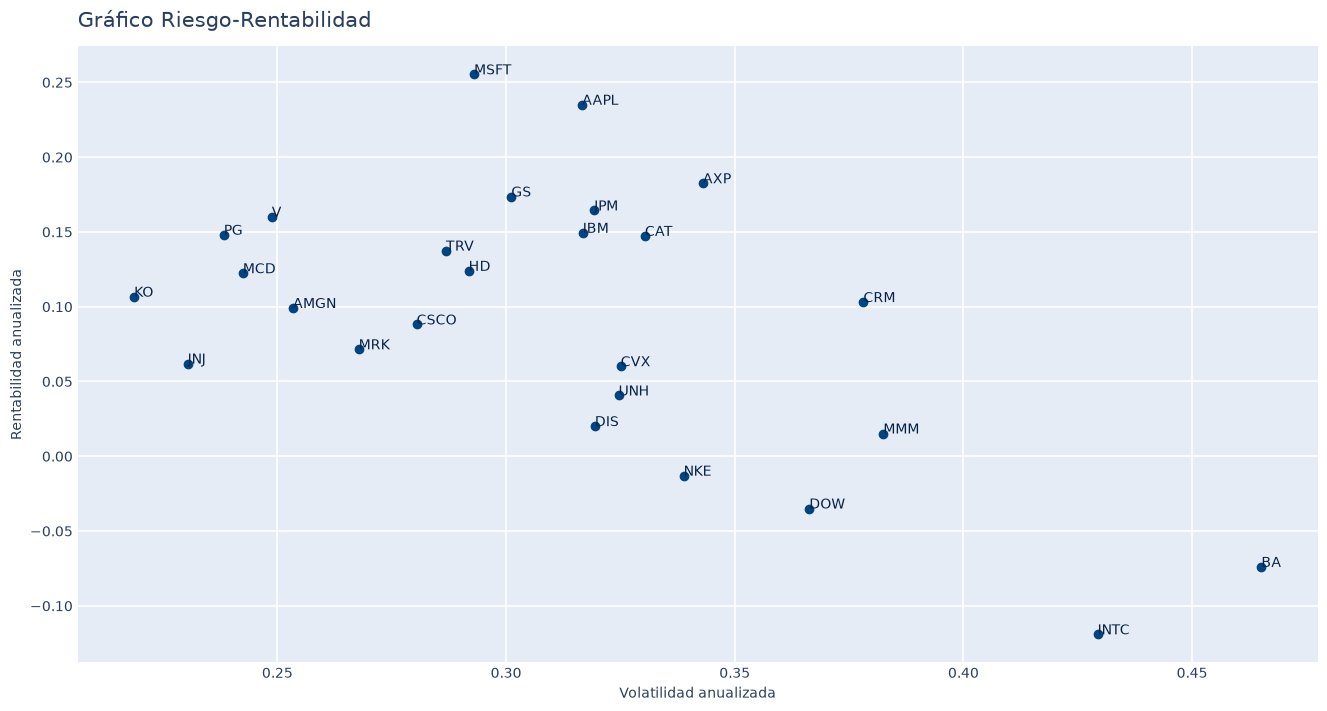

In [36]:
# Gráfico de riesgo-rentabilidad
fig, ax = plt.subplots(figsize=(16, 8))

ax.scatter(tabla_final["Volatilidad anualizada"], tabla_final["Rentabilidad anualizada"], color=paleta_bbva["azul_logotipo"])

for activo in tabla_final.index:
    ax.annotate(activo,(tabla_final.loc[activo, "Volatilidad anualizada"], tabla_final.loc[activo, "Rentabilidad anualizada"]), color=paleta_bbva["azul_oscuro_digital"])

plt.xlabel("Volatilidad anualizada")
plt.ylabel("Rentabilidad anualizada")
plt.title("Gráfico Riesgo-Rentabilidad")
plt.show()

### Conclusiones: gráfico riesgo-rentabilidad

En teoría, a mayor riesgo debería exigirse mayor rentabilidad, pero en esta muestra esa relación no se cumple: hay activos muy volátiles con rentabilidad negativa y activos poco volátiles con buena rentabilidad. Los activos más eficientes están en la zona superior izquierda del gráfico, con mucha rentabilidad para el riesgo que asumen: MSFT (25,1 % de rentabilidad anualizada con un 28,9 % de volatilidad), AAPL (22,4 % con 31,9 %), GS (16,7 % con 29,8 %), V (14,3 % con 25,0 %) y PG (11,5 % con 23,5 %).

En la zona inferior derecha están los menos eficientes, que asumen más riesgo y obtienen menos: INTC (−12,3 % con 43,0 %), BA (−7,5 % con 46,1 %), DOW (−6,8 % con 36,6 %) y MMM (0,9 % con 43,2 %, aunque su volatilidad está inflada por los datos erróneos de junio de 2020). Un inversor racional no debería elegirlos frente a alternativas con más rentabilidad y menos riesgo, salvo que aporten diversificación a la cartera.

KO (21,2 %) y JNJ (22,9 %) son los activos menos volátiles, pero con rentabilidades moderadas (7,1 % y 3,1 %), un perfil claramente defensivo. Hay que recordar que estos resultados dependen del periodo analizado, alcista y favorable a las tecnológicas y las financieras, y que la rentabilidad pasada no garantiza la futura.

## 13. COMPARACIÓN DE LOS RATIOS

Representamos los ratios de Sharpe y Sortino para poder comparar visualmente la relación entre rentabilidad y riesgo.


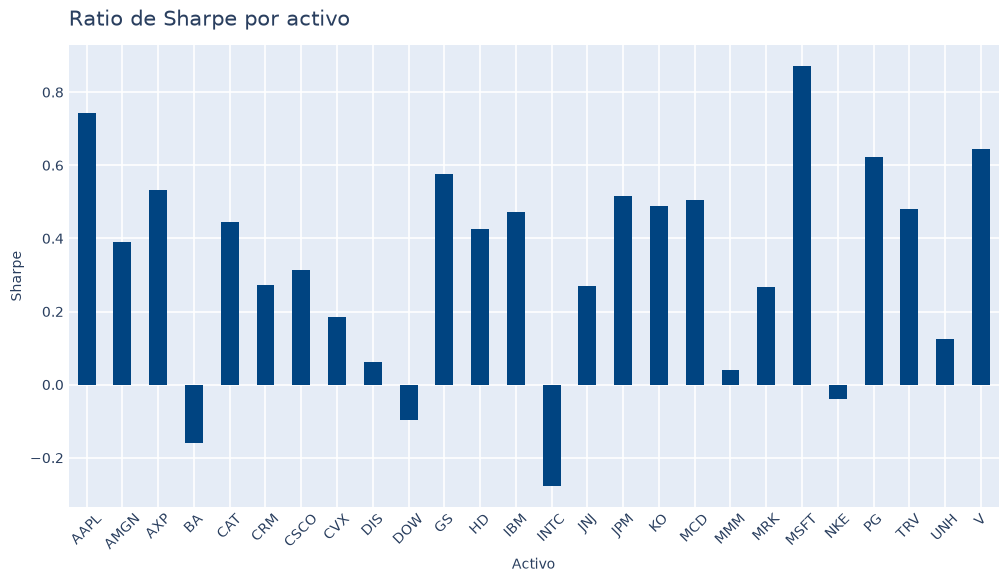

In [37]:
# Ratio de Sharpe
tabla_final["Sharpe"].plot(kind="bar", figsize=(12, 6), color=paleta_bbva["azul_logotipo"])

plt.title("Ratio de Sharpe por activo")
plt.xlabel("Activo")
plt.ylabel("Sharpe")
plt.xticks(rotation=45)
plt.show()

### Conclusiones: ratio de Sharpe

El ratio de Sharpe mide la rentabilidad obtenida por cada unidad de riesgo total; cuanto más alto, mejor compensado está el riesgo. MSFT lidera con claridad (0,87), seguido de AAPL (0,70), V (0,57), GS (0,56), AXP (0,51), PG (0,49), JPM (0,47) y CAT (0,42). Son los únicos ocho activos con un Sharpe superior a 0,4: combinan rentabilidades elevadas con una volatilidad moderada.

INTC (−0,29), DOW (−0,19), BA (−0,16) y NKE (−0,02) tienen un Sharpe negativo: han perdido valor asumiendo riesgo. Los activos con un Sharpe entre 0 y 0,15 (MMM, CVX, DIS, UNH, JNJ y MRK) apenas han compensado el riesgo asumido.

Al usar un tipo libre de riesgo del 0 %, los Sharpe están sobrestimados en valor absoluto, ya que los tipos de interés fueron positivos en buena parte del periodo, sobre todo entre 2022 y 2025. Sin embargo, el orden entre los activos se mantendría.

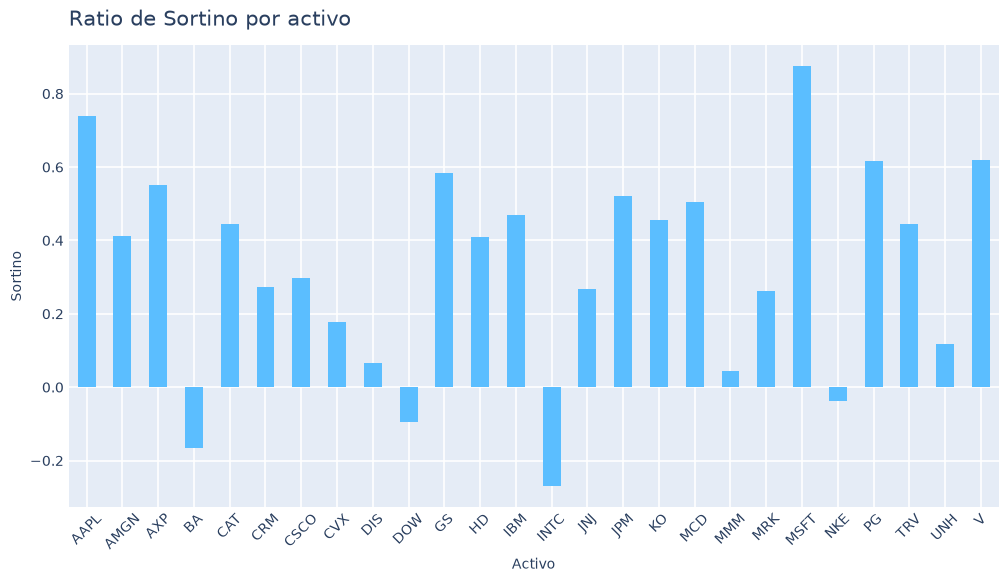

In [38]:
# Ratio de Sortino
tabla_final["Sortino"].plot(kind="bar", figsize=(12, 6), color=paleta_bbva["azul_celeste_aqua"])

plt.title("Ratio de Sortino por activo")
plt.xlabel("Activo")
plt.ylabel("Sortino")
plt.xticks(rotation=45)
plt.show()

### Conclusiones: ratio de Sortino

El ratio de Sortino solo penaliza la volatilidad a la baja, que es la que realmente preocupa al inversor. Sus resultados son prácticamente iguales a los del Sharpe, con diferencias que no superan 0,04: MSFT (0,86), AAPL (0,70), GS (0,56), V (0,53) y AXP (0,52) siguen a la cabeza, e INTC, DOW, BA y NKE siguen en negativo. Que los dos ratios ordenen los activos de la misma forma refuerza las conclusiones.

Las pequeñas diferencias también aportan información: cuando el Sortino es menor que el Sharpe, una parte mayor del riesgo corresponde a caídas. Es lo que ocurre en V, TRV y KO, mientras que en AXP e INTC sucede lo contrario. En general, los activos con mejores ratios son empresas de calidad, con beneficios estables y una posición dominante en su sector, y los peores (INTC, BA, NKE y DOW) son empresas con problemas propios, como crisis de producto o pérdida de competitividad.

## 14. MATRIZ DE CORRELACIONES

Como análisis adicional, representamos la matriz de correlaciones de las rentabilidades de los activos.


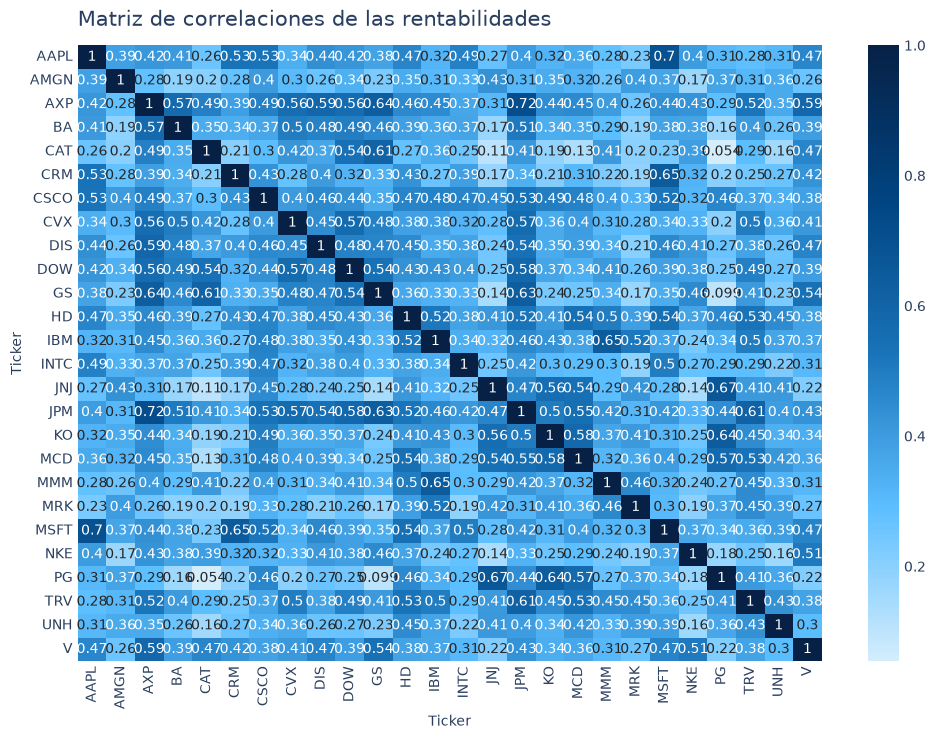

In [39]:
# Matriz de correlaciones de las rentabilidades
correlation_mat = rentabilidades.corr()

plt.figure(figsize=(12, 8))
sns.heatmap(correlation_mat, annot=True, cmap=cmap_bbva)
plt.title("Matriz de correlaciones de las rentabilidades")
plt.show()

### Conclusiones: matriz de correlaciones

Todas las correlaciones entre activos son positivas, con una media de 0,33 y valores entre 0,05 y 0,74. Esto refleja el factor común de mercado: los activos tienden a moverse en la misma dirección, sobre todo en las crisis. Las correlaciones más altas aparecen entre empresas del mismo sector: AXP-JPM (0,74) y GS-JPM (0,63) en el sector financiero, y AAPL-MSFT (0,64) y CRM-MSFT (0,62) en el tecnológico. Combinar estos activos aporta poca diversificación, porque comparten los mismos riesgos.

Las correlaciones más bajas aparecen entre sectores con motores económicos distintos, como CAT-PG (0,05), GS-PG (0,09) o BA-PG (0,12), es decir, un activo industrial o financiero combinado con uno de consumo básico. Son las combinaciones con más potencial de diversificación. Las correlaciones de DOW, MMM y MRK con el resto son algo más bajas (por ejemplo, DOW-MMM, 0,05), pero en parte puede deberse a los datos erróneos de junio de 2020 y no a una diversificación real.

Como ninguna correlación es negativa, diversificar reduce el riesgo específico de cada empresa, pero no el riesgo de mercado: una cartera con estos activos seguiría cayendo en una crisis general, aunque menos que un activo individual.

## 15. CONCLUSIONES GENERALES

El periodo 2018-2025 ha sido alcista para el mercado estadounidense (la mitad de los activos sube más de un 70 %), pero con caídas comunes muy marcadas en marzo de 2020, en 2022 y en abril de 2025. Buena parte del comportamiento de cada activo se explica por el mercado, es decir, por el riesgo sistemático.

Rentabilidad y riesgo no han ido de la mano. Los activos más eficientes, con mayor Sharpe y Sortino, han sido MSFT, AAPL, V, GS, AXP y PG, mientras que INTC, BA, DOW y NKE han perdido valor asumiendo mucho riesgo. Para valorar un activo no basta con mirar su rentabilidad: hay que medirla en relación con el riesgo asumido.

El riesgo tampoco es constante. La volatilidad se concentra en determinados periodos y se dispara en las crisis, y el drawdown ofrece una visión del riesgo más cercana a la experiencia del inversor que la desviación típica. Los activos defensivos (PG, JNJ, KO) tienen menor volatilidad y caídas más pequeñas, mientras que los cíclicos o con problemas propios (BA, INTC, DOW) sufren las mayores caídas.

Las correlaciones son positivas y moderadas, por lo que combinar activos de sectores distintos reduce el riesgo específico, pero no elimina el riesgo de mercado.

Por último, el análisis tiene algunas limitaciones: el dataset contiene datos erróneos en junio de 2020 que inflan el riesgo de algunos activos (MMM, MRK, IBM y DOW), se usa un tipo libre de riesgo del 0 %, que sobrestima los ratios, y todo se basa en un único periodo histórico, cuya rentabilidad no garantiza la futura.

## 16. ANÁLISIS DE VARIABLES CUALITATIVAS (YFINANCE)

Hasta aquí el análisis ha sido puramente cuantitativo (precios, rentabilidades y riesgo). En esta sección se añaden variables **cualitativas** de cada activo disponibles en la librería `yfinance`, para contextualizar los números:

- **Perfil del activo:** sector, industria, país, consenso de analistas y riesgo de gobierno corporativo.
- **Holders principales:** reparto del capital entre *insiders* (directivos y consejeros) e instituciones.
- **Holders institucionales:** quiénes son los mayores accionistas y cuánto capital concentran.
- **Splits:** desdoblamientos de acciones, que explican saltos bruscos en precios no ajustados.
- **Dividendos:** pagos a los accionistas, rentabilidad por dividendo y evolución en el tiempo.

In [40]:
# Librería yfinance (si no está instalada: pip install yfinance)
import yfinance as yf
from IPython.display import display

tickers = list(datos.columns)
activos_yf = {t: yf.Ticker(t) for t in tickers}

# Rango temporal del dataset (sin zona horaria, para poder cruzarlo con los datos de yfinance)
indice_precios = pd.DatetimeIndex(datos.index)
if indice_precios.tz is not None:
    indice_precios = indice_precios.tz_localize(None)
inicio_periodo, fin_periodo = indice_precios.min(), indice_precios.max()

# Rentabilidades diarias con el mismo índice sin zona horaria
rent_sin_tz = rentabilidades.copy()
rent_sin_tz.index = indice_precios

def sin_zona_horaria(serie):
    """Quita la zona horaria del índice (yfinance la devuelve) para poder cruzar con `datos`."""
    serie = serie.copy()
    if getattr(serie.index, "tz", None) is not None:
        serie.index = serie.index.tz_localize(None)
    return serie

def obtener(activo, atributo):
    """Descarga un atributo de yfinance sin que un fallo en un activo pare el notebook."""
    try:
        return getattr(activos_yf[activo], atributo)
    except Exception as e:
        print(f"[aviso] {activo}: no se pudo obtener '{atributo}' ({type(e).__name__})")
        return None

### 16.1 Perfil cualitativo de los activos

Sector, industria, país, tamaño, beta, consenso de analistas y riesgo de gobierno corporativo (puntuación de 1 a 10, donde 1 es el menor riesgo). Sirve para ver de un vistazo qué tipo de empresa hay detrás de cada serie de precios.

In [41]:
# Información general de cada activo (foto actual)
campos_perfil = {
    "longName": "Nombre",
    "sector": "Sector",
    "industry": "Industria",
    "country": "País",
    "marketCap": "Capitalización ($)",
    "beta": "Beta",
    "recommendationKey": "Recomendación analistas",
    "numberOfAnalystOpinions": "Nº analistas",
    "overallRisk": "Riesgo gobierno corporativo (1-10)",}

info = {}
for t in tickers:
    d = obtener(t, "info")
    info[t] = d if isinstance(d, dict) else {}

perfil = pd.DataFrame(
    {t: {nombre: info[t].get(campo) for campo, nombre in campos_perfil.items()} for t in tickers}).T
perfil.index.name = "Activo"
perfil

,Nombre,Sector,Industria,País,Capitalización ($),Beta,Recomendación analistas,Nº analistas,Riesgo gobierno corporativo (1-10)
Activo,,,,,,,,,
AAPL,Apple Inc.,Technology,Consumer Electronics,United States,5079143284736,1.089,buy,38,1
AMGN,Amgen Inc.,Healthcare,Drug Manufacturers - General,United States,258681602048,0.417,hold,29,3
AXP,American Express Company,Financial Services,Credit Services,United States,223018893312,1.077,buy,24,5
BA,The Boeing Company,Industrials,Aerospace & Defense,United States,140263636992,1.331,strong_buy,26,9
CAT,Caterpillar Inc.,Industrials,Farm & Heavy Construction Machinery,United States,271805743104,1.64,buy,26,3
CRM,"Salesforce, Inc.",Technology,Software - Application,United States,186911522816,1.233,buy,53,6
CSCO,"Cisco Systems, Inc.",Technology,Communication Equipment,United States,408491425792,1.002,buy,25,3
CVX,Chevron Corporation,Energy,Oil & Gas Integrated,United States,423288995840,0.453,buy,24,1
DIS,The Walt Disney Company,Communication Services,Entertainment,United States,205389398016,1.426,strong_buy,32,2


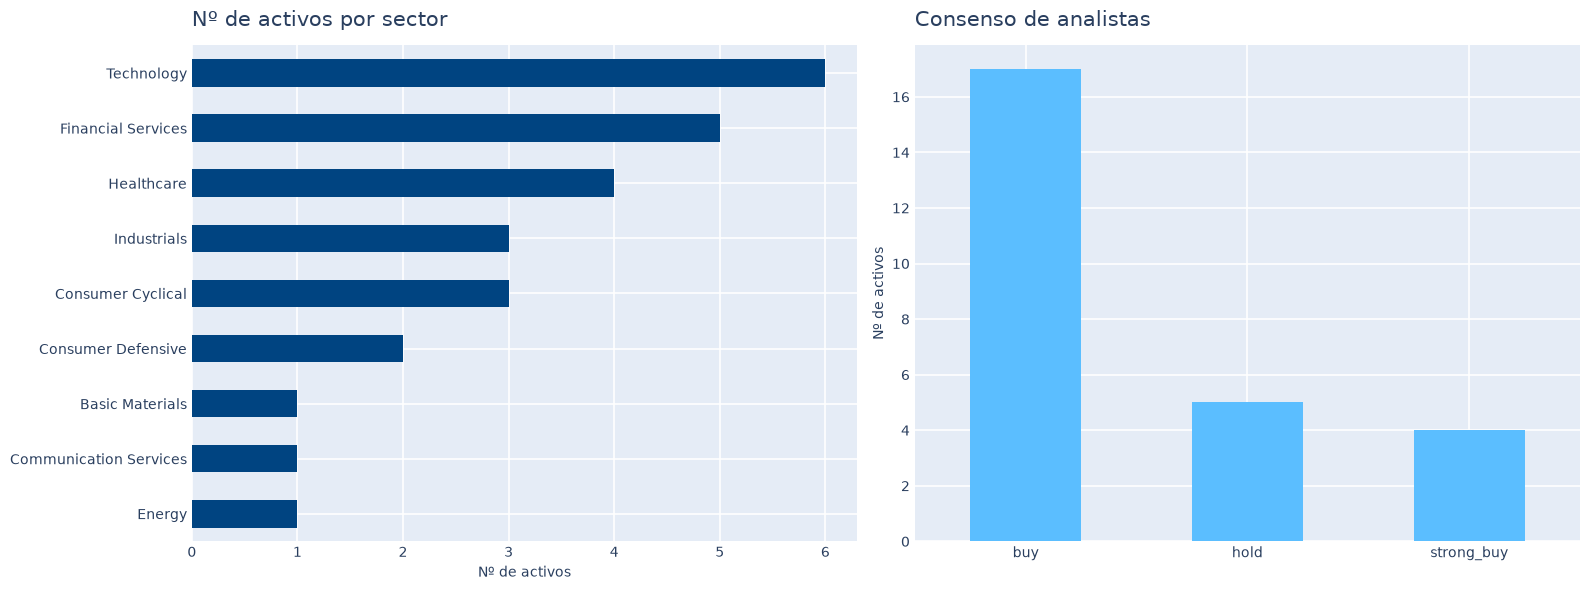

In [42]:
# Representación del perfil: composición por sector y consenso de analistas
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sectores = perfil["Sector"].value_counts()
if len(sectores) > 0:
    sectores.sort_values().plot(kind="barh", ax=axes[0], color=paleta_bbva["azul_logotipo"])
axes[0].set_title("Nº de activos por sector")
axes[0].set_xlabel("Nº de activos")
axes[0].set_ylabel("")

recomendaciones = perfil["Recomendación analistas"].value_counts()
if len(recomendaciones) > 0:
    recomendaciones.plot(kind="bar", ax=axes[1], color=paleta_bbva["azul_celeste_aqua"])
axes[1].set_title("Consenso de analistas")
axes[1].set_xlabel("")
axes[1].set_ylabel("Nº de activos")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

### 16.2 Holders principales: insiders e instituciones

Porcentaje del capital en manos de **insiders** (directivos y consejeros) y de **instituciones** (fondos, gestoras, aseguradoras...). Muchos insiders suelen indicar alineación de intereses con el accionista; mucha presencia institucional indica un valor muy seguido por el "dinero profesional". Los porcentajes pueden sumar más de 100 % porque una misma acción puede computarse en varias instituciones.

In [43]:
# Holders principales (insiders e instituciones)
filas = {}
for t in tickers:
    mh = obtener(t, "major_holders")
    fila = mh["Value"].to_dict() if isinstance(mh, pd.DataFrame) and "Value" in mh.columns else {}
    filas[t] = {"Insiders (%)": fila.get("insidersPercentHeld", info[t].get("heldPercentInsiders")),
        "Instituciones (%)": fila.get("institutionsPercentHeld", info[t].get("heldPercentInstitutions")),
        "Instituciones s/ free float (%)": fila.get("institutionsFloatPercentHeld"),
        "Nº instituciones": fila.get("institutionsCount"),}

tabla_holders = pd.DataFrame.from_dict(
    filas, orient="index",
    columns=["Insiders (%)", "Instituciones (%)", "Instituciones s/ free float (%)", "Nº instituciones"]).apply(pd.to_numeric, errors="coerce")
tabla_holders.index.name = "Activo"

tabla_holders.style.format({
    "Insiders (%)": "{:.2%}",
    "Instituciones (%)": "{:.2%}",
    "Instituciones s/ free float (%)": "{:.2%}",
    "Nº instituciones": "{:,.0f}",}, na_rep="-")

,Insiders (%),Instituciones (%),Instituciones s/ free float (%),Nº instituciones
Activo,,,,
AAPL,1.65%,66.57%,67.69%,"7,739"
AMGN,0.23%,85.02%,85.22%,"4,095"
AXP,22.72%,65.22%,84.39%,"3,725"
BA,0.06%,76.72%,76.76%,"3,106"
CAT,0.22%,73.74%,73.90%,"4,839"
CRM,2.98%,87.31%,89.99%,"3,620"
CSCO,0.05%,83.09%,83.14%,"5,122"
CVX,4.83%,72.08%,75.74%,"5,094"
DIS,0.07%,78.84%,78.89%,"3,869"


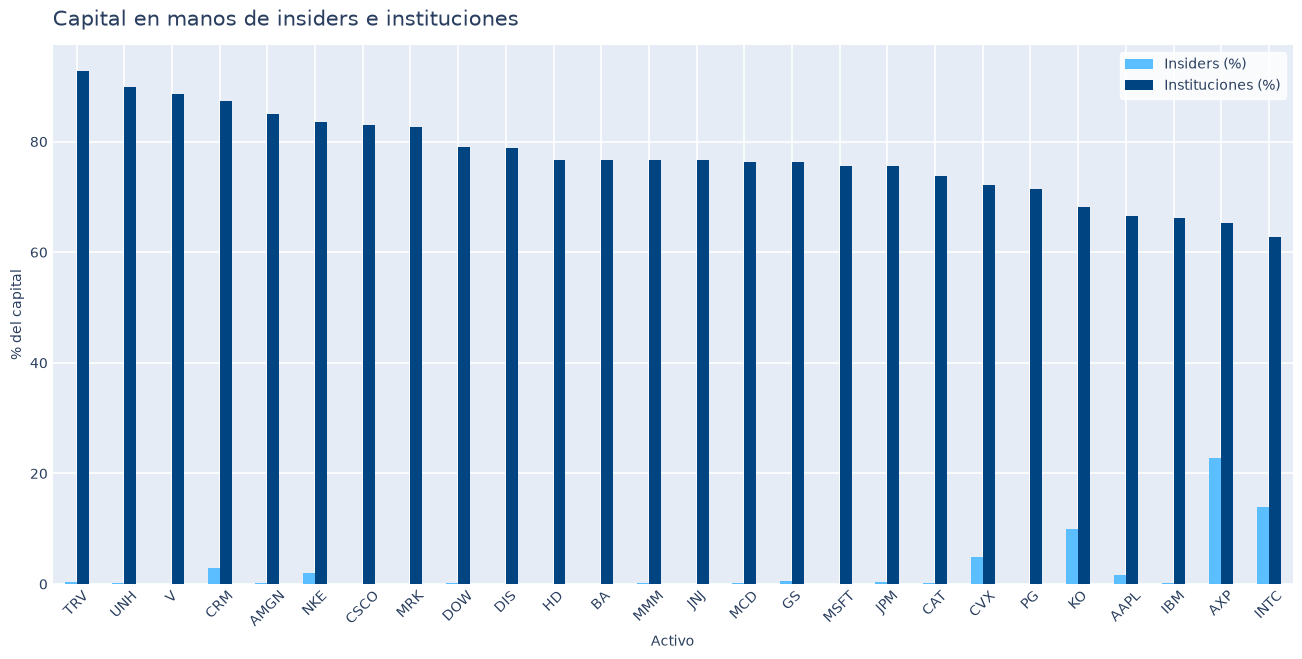

In [44]:
# Insiders vs instituciones por activo
plot_holders = (tabla_holders[["Insiders (%)", "Instituciones (%)"]] * 100).dropna(how="all")

if plot_holders.empty:
    print("No hay datos de holders principales para representar.")
else:
    plot_holders = plot_holders.sort_values("Instituciones (%)", ascending=False)
    plot_holders.plot(kind="bar", figsize=(16, 7), color=[paleta_bbva["azul_celeste_aqua"], paleta_bbva["azul_logotipo"]])
    plt.title("Capital en manos de insiders e instituciones")
    plt.xlabel("Activo")
    plt.ylabel("% del capital")
    plt.xticks(rotation=45)
    plt.legend()
    plt.show()

### 16.3 Holders institucionales

Quiénes son los mayores accionistas institucionales de cada activo, cuánto concentran los 5 y los 10 primeros, y qué gestoras se repiten en muchos activos. Que unas pocas gestoras sean accionistas de casi todos los valores es una fuente de riesgo común que no aparece en los precios, pero que ayuda a entender por qué las correlaciones son positivas.

In [45]:
# Holders institucionales de cada activo
holders_inst = {t: obtener(t, "institutional_holders") for t in tickers}

def columna_pct(df):
    """Nombre de la columna con el % del capital (cambia según la versión de yfinance)."""
    return next((c for c in ["pctHeld", "% Out"] if c in df.columns), None)

filas = {}
for t, df in holders_inst.items():
    if not isinstance(df, pd.DataFrame) or df.empty or columna_pct(df) is None or "Holder" not in df.columns:
        continue
    col = columna_pct(df)
    df = df.sort_values(col, ascending=False)
    filas[t] = {"Mayor holder": df.iloc[0]["Holder"],
        "% mayor holder": df.iloc[0][col],
        "% top 5": df[col].head(5).sum(),
        "% top 10": df[col].head(10).sum()}

tabla_inst = pd.DataFrame.from_dict(
    filas, orient="index",
    columns=["Mayor holder", "% mayor holder", "% top 5", "% top 10"])
tabla_inst.index.name = "Activo"

if tabla_inst.empty:
    print("No se han obtenido holders institucionales.")
else:
    for c in ["% mayor holder", "% top 5", "% top 10"]:
        tabla_inst[c] = pd.to_numeric(tabla_inst[c], errors="coerce")
    display(tabla_inst.style.format({
        "% mayor holder": "{:.2%}", "% top 5": "{:.2%}", "% top 10": "{:.2%}"}, na_rep="-"))

,Mayor holder,% mayor holder,% top 5,% top 10
Activo,,,,
AAPL,Blackrock Inc.,7.97%,23.58%,31.91%
AMGN,Blackrock Inc.,9.13%,29.70%,42.00%
AXP,"Berkshire Hathaway, Inc",22.61%,41.51%,49.46%
BA,Blackrock Inc.,7.70%,30.30%,41.02%
CAT,Blackrock Inc.,8.26%,28.06%,37.25%
CRM,Blackrock Inc.,8.84%,25.86%,34.30%
CSCO,Blackrock Inc.,9.10%,26.84%,36.46%
CVX,Blackrock Inc.,7.84%,28.09%,36.51%
DIS,Blackrock Inc.,7.93%,26.12%,34.74%


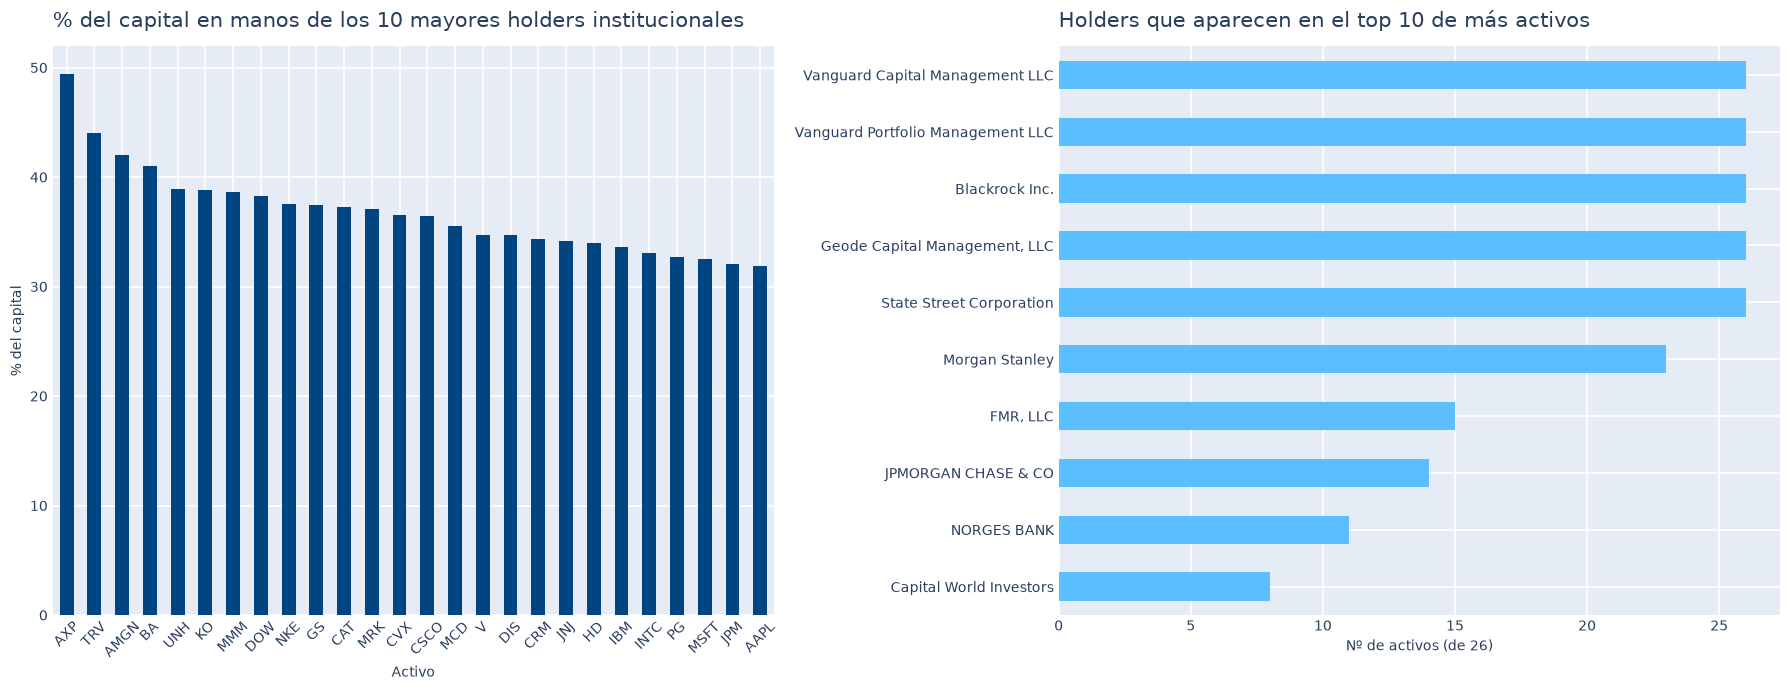

In [46]:
# Concentración institucional (top 10) y gestoras que más se repiten entre los activos
if not tabla_inst.empty:
    frecuencia = {}
    for t, df in holders_inst.items():
        if not isinstance(df, pd.DataFrame) or df.empty or columna_pct(df) is None or "Holder" not in df.columns:
            continue
        for h in df.sort_values(columna_pct(df), ascending=False).head(10)["Holder"]:
            frecuencia[h] = frecuencia.get(h, 0) + 1
    frecuencia = pd.Series(frecuencia, dtype=float).sort_values(ascending=False)

    fig, axes = plt.subplots(1, 2, figsize=(18, 7))

    (tabla_inst["% top 10"].dropna().sort_values(ascending=False) * 100).plot(
        kind="bar", ax=axes[0], color=paleta_bbva["azul_logotipo"])
    axes[0].set_title("% del capital en manos de los 10 mayores holders institucionales")
    axes[0].set_xlabel("Activo")
    axes[0].set_ylabel("% del capital")
    axes[0].tick_params(axis="x", rotation=45)

    if len(frecuencia) > 0:
        frecuencia.head(10).sort_values().plot(kind="barh", ax=axes[1], color=paleta_bbva["azul_celeste_aqua"])
    axes[1].set_title("Holders que aparecen en el top 10 de más activos")
    axes[1].set_xlabel(f"Nº de activos (de {len(tabla_inst)})")
    axes[1].set_ylabel("")

    plt.tight_layout()
    plt.show()

## DETALLE DE HOLDERS INSTITUCIONALES DE ACTIVOS QUE HEMOS ELEGIDO

## MICROSOFT

,Date Reported,Holder,pctHeld,Shares,Value,pctChange
0,2026-06-30,Blackrock Inc.,0.0818,607367113,337574633991,0.0237
1,2026-06-30,Vanguard Capital Management LLC,0.0653,485192007,269669711567,0.0055
2,2026-06-30,State Street Corporation,0.0425,315653206,175440048041,0.0292
3,2026-06-30,"Geode Capital Management, LLC",0.0255,189632090,105397513307,0.0060
4,2026-06-30,"FMR, LLC",0.0250,185960066,103356602412,-0.0224
5,2026-06-30,Vanguard Portfolio Management LLC,0.0227,168407641,93600964812,0.0055
6,2026-06-30,JPMORGAN CHASE & CO,0.0182,135173516,75129438542,0.0633
7,2026-06-30,Morgan Stanley,0.0172,127674661,70961575025,0.0224
8,2026-06-30,NORGES BANK,0.0138,102732956,57098975690,-0.0194
9,2026-06-30,Invesco Ltd.,0.0135,100247890,55717776038,0.0152


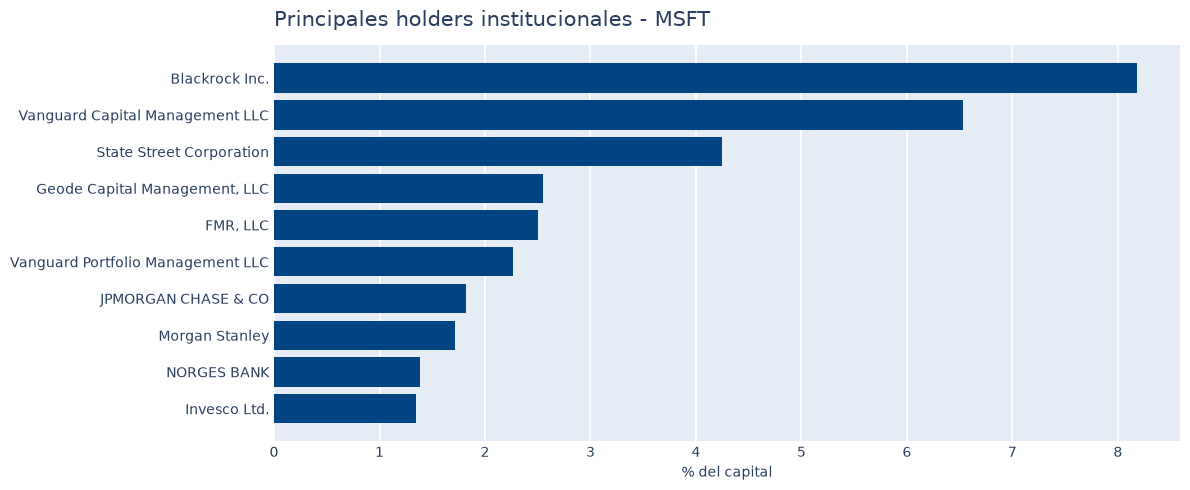

In [47]:
# Detalle de los holders institucionales de CAO
activo_ejemplo = "MSFT" if "MSFT" in tickers else tickers[0]
def ver_holders_institucionales(activo, top=10):
    df = holders_inst.get(activo)
    if not isinstance(df, pd.DataFrame) or df.empty or columna_pct(df) is None or "Holder" not in df.columns:
        print(f"No hay holders institucionales disponibles para {activo}.")
        return
    col = columna_pct(df)
    df = df.sort_values(col, ascending=False).head(top)
    display(df)

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.barh(df["Holder"].astype(str)[::-1], df[col][::-1] * 100, color=paleta_bbva["azul_logotipo"])
    ax.set_title(f"Principales holders institucionales - {activo}")
    ax.set_xlabel("% del capital")
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()

ver_holders_institucionales(activo_ejemplo)

## GOLDMAN SACHS

,Date Reported,Holder,pctHeld,Shares,Value,pctChange
0,2026-06-30,Blackrock Inc.,0.0829,23900376,22179548928,-0.0037
1,2026-06-30,State Street Corporation,0.0653,18830464,17474670592,-0.0221
2,2026-06-30,Vanguard Capital Management LLC,0.0639,18425670,17099021760,0.0021
3,2026-06-30,JPMORGAN CHASE & CO,0.0279,8039070,7460256960,0.1141
4,2026-06-30,Vanguard Portfolio Management LLC,0.0250,7215421,6695910688,0.0010
5,2026-06-30,Morgan Stanley,0.0244,7030974,6524743872,0.0314
6,2026-06-30,"Fisher Asset Management, LLC",0.0241,6964113,6462696864,0.0200
7,2026-06-30,"Geode Capital Management, LLC",0.0241,6948585,6448286880,-0.0234
8,2026-06-30,Bank of America Corporation,0.0232,6680811,6199792608,0.0350
9,2026-06-30,"FMR, LLC",0.0134,3866640,3588241920,0.1572


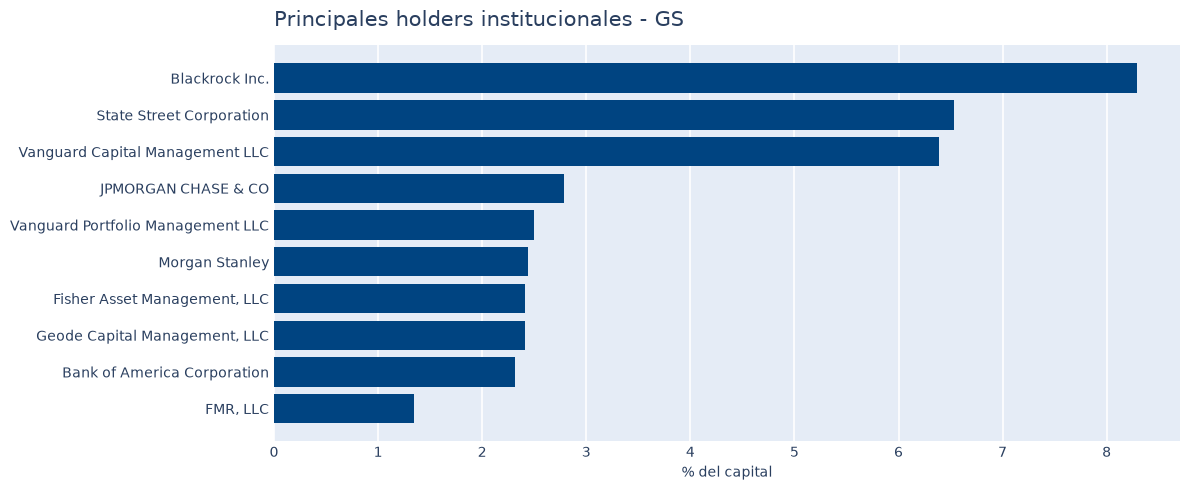

In [48]:
# Detalle de los holders institucionales de GS
activo_ejemplo = "GS" if "GS" in tickers else tickers[0]
def ver_holders_institucionales(activo, top=10):
    df = holders_inst.get(activo)
    if not isinstance(df, pd.DataFrame) or df.empty or columna_pct(df) is None or "Holder" not in df.columns:
        print(f"No hay holders institucionales disponibles para {activo}.")
        return
    col = columna_pct(df)
    df = df.sort_values(col, ascending=False).head(top)
    display(df)

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.barh(df["Holder"].astype(str)[::-1], df[col][::-1] * 100, color=paleta_bbva["azul_logotipo"])
    ax.set_title(f"Principales holders institucionales - {activo}")
    ax.set_xlabel("% del capital")
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()

ver_holders_institucionales(activo_ejemplo)

## CATERPILLAR

,Date Reported,Holder,pctHeld,Shares,Value,pctChange
0,2026-06-30,Blackrock Inc.,0.0826,37991505,22464376442,0.0221
1,2026-06-30,State Street Corporation,0.0748,34392316,20336176030,-0.0140
2,2026-06-30,Vanguard Capital Management LLC,0.0654,30077764,17784981486,-0.0052
3,2026-06-30,State Farm Mutual Automobile Insurance Co,0.0316,14509304,8579351278,-0.0038
4,2026-06-30,Vanguard Portfolio Management LLC,0.0262,12026244,7111117930,0.0274
5,2026-06-30,"Geode Capital Management, LLC",0.0243,11175493,6608068874,0.0043
6,2026-06-30,"Fisher Asset Management, LLC",0.0216,9942521,5879012545,0.0170
7,2026-06-30,Morgan Stanley,0.0163,7504426,4437367002,0.0006
8,2026-06-30,JPMORGAN CHASE & CO,0.0159,7325731,4331704650,1.4913
9,2026-06-30,Gates Foundation Trust,0.0138,6353614,3756891880,0.0000


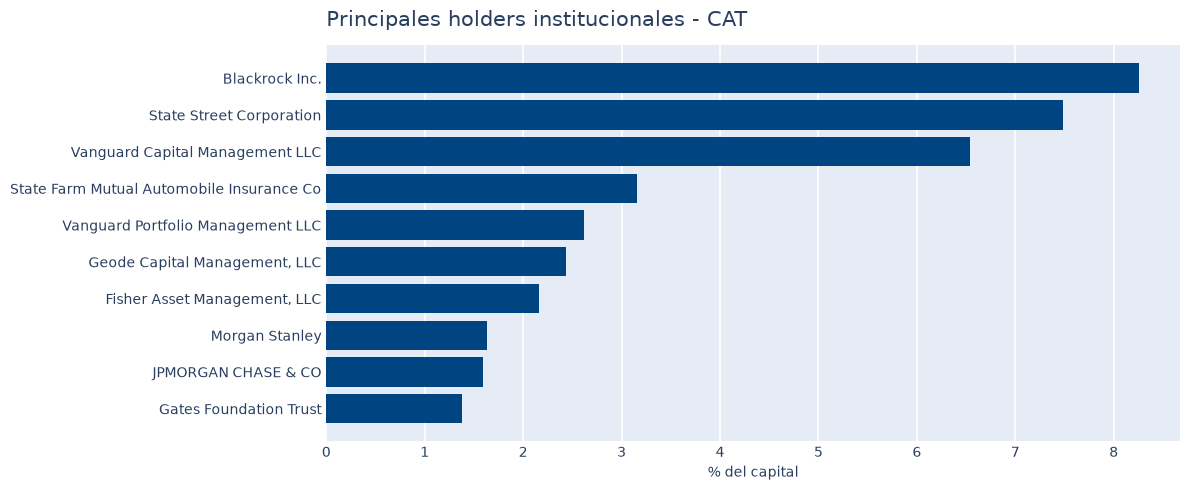

In [49]:
# Detalle de los holders institucionales de CAT
activo_ejemplo = "CAT" if "CAT" in tickers else tickers[0]
def ver_holders_institucionales(activo, top=10):
    df = holders_inst.get(activo)
    if not isinstance(df, pd.DataFrame) or df.empty or columna_pct(df) is None or "Holder" not in df.columns:
        print(f"No hay holders institucionales disponibles para {activo}.")
        return
    col = columna_pct(df)
    df = df.sort_values(col, ascending=False).head(top)
    display(df)

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.barh(df["Holder"].astype(str)[::-1], df[col][::-1] * 100, color=paleta_bbva["azul_logotipo"])
    ax.set_title(f"Principales holders institucionales - {activo}")
    ax.set_xlabel("% del capital")
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()

ver_holders_institucionales(activo_ejemplo)

### 16.4 Splits

Un *split* multiplica el número de acciones y divide el precio (un split 4:1 divide el precio entre 4). Si la serie de precios no está bien ajustada, el split aparece como un salto brusco que **parece** una rentabilidad extrema, pero no lo es. Por eso se cruzan los splits con las rentabilidades diarias del dataset: así se puede comprobar si los datos atípicos comentados en las conclusiones de las secciones anteriores coinciden con un evento corporativo.

In [50]:
#splits de los activos
splits = {}
for t in tickers:
    s = obtener(t, "splits")
    
    if isinstance(s, pd.Series) and len(s) > 0:
        s = sin_zona_horaria(s)
        splits[t] = s

#1.TABLA RESUMEN: TODOS LOS ACTIVOS
resumen_splits = []

for t in tickers:   
    s = splits.get(t, pd.Series(dtype=float))
    
    #solo splits dentro del periodo analizado
    if len(s) > 0:
        s_periodo = s[(s.index >= inicio_periodo) & (s.index <= fin_periodo)]
    else:
        s_periodo = s   
    if len(s_periodo) > 0:  
        resumen_splits.append({"Activo": t,
            "Nº splits en periodo": len(s_periodo),
            "Fechas": ", ".join(
                fecha.strftime("%Y-%m-%d")
                for fecha in s_periodo.index),
            "Ratios": ", ".join(
                f"{ratio:g}:1"
                for ratio in s_periodo.values),
            "Tiene split": "Sí"})       
    else:        
        resumen_splits.append({"Activo": t,
            "Nº splits en periodo": 0,
            "Fechas": "-",
            "Ratios": "-", "Tiene split": "No"})

tabla_resumen_splits = pd.DataFrame(resumen_splits)
tabla_resumen_splits = tabla_resumen_splits.sort_values(["Tiene split", "Activo"], ascending=[False, True]).reset_index(drop=True)

display(tabla_resumen_splits)

#tabla de los splits existentes
filas_splits = []
for t, s in splits.items():   
    s_periodo = s[(s.index >= inicio_periodo) & (s.index <= fin_periodo)]
    for fecha, ratio in s_periodo.items():        
        tipo = "Split directo" if ratio > 1 else "Contrasplit"        
        filas_splits.append({"Activo": t, "Fecha": fecha, "Ratio": ratio, "Tipo": tipo})
tabla_splits = pd.DataFrame(filas_splits, columns=["Activo", "Fecha", "Ratio", "Tipo"])

if not tabla_splits.empty: 
    tabla_splits = tabla_splits.sort_values("Fecha").reset_index(drop=True)   
    display(tabla_splits.style.format({"Fecha": "{:%Y-%m-%d}", "Ratio": "{:g}:1"}))   
else:
    print("No se han encontrado splits dentro del periodo analizado.")

,Activo,Nº splits en periodo,Fechas,Ratios,Tiene split
0,AAPL,1,2020-08-31,4:1,Sí
1,IBM,1,2021-11-04,1.046:1,Sí
2,MMM,1,2024-04-01,1.196:1,Sí
3,MRK,1,2021-06-03,1.048:1,Sí
4,AMGN,0,-,-,No
5,AXP,0,-,-,No
6,BA,0,-,-,No
7,CAT,0,-,-,No
8,CRM,0,-,-,No
9,CSCO,0,-,-,No


,Activo,Fecha,Ratio,Tipo
0,AAPL,2020-08-31,4:1,Split directo
1,MRK,2021-06-03,1.048:1,Split directo
2,IBM,2021-11-04,1.046:1,Split directo
3,MMM,2024-04-01,1.196:1,Split directo


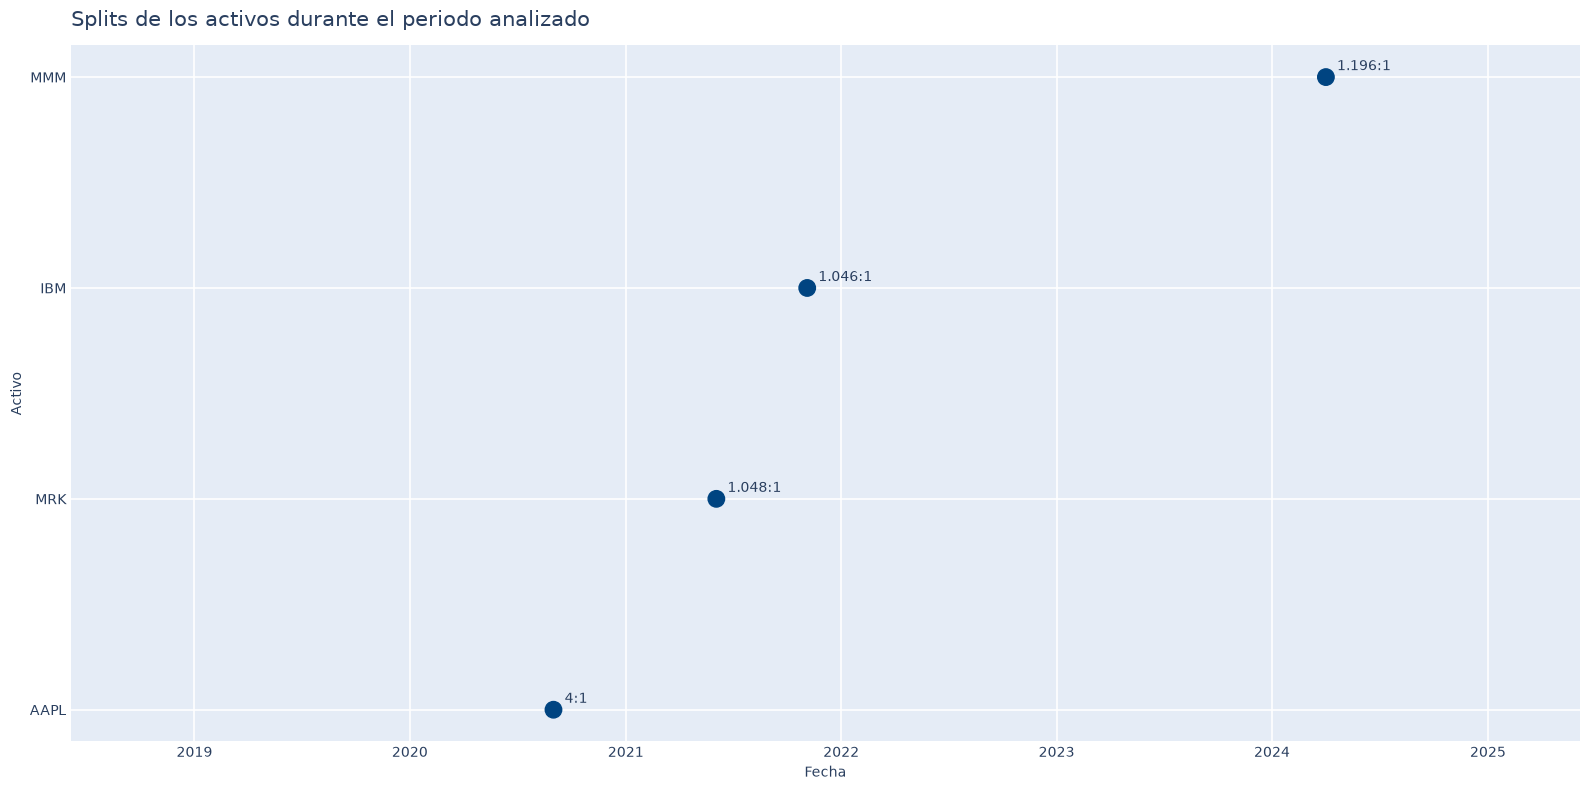

In [51]:
#Graficos de splits
if tabla_splits.empty:
    print("No hay splits que representar.")
else:   
    fig, ax = plt.subplots(figsize=(16, 8))   
    colores = [
        paleta_bbva["azul_logotipo"]
        if tipo == "Split directo"
        else paleta_bbva["azul_celeste_aqua"]
        for tipo in tabla_splits["Tipo"]]
    
    ax.scatter(tabla_splits["Fecha"], tabla_splits["Activo"], s=140, c=colores, zorder=3)
    
    #ponemos el ratio al lado de cada punto
    for _, fila in tabla_splits.iterrows():        
        ax.annotate(f"{fila['Ratio']:g}:1", (fila["Fecha"], fila["Activo"]), textcoords="offset points", xytext=(8, 5))
    
    ax.set_xlim(inicio_periodo, fin_periodo)
    ax.set_title("Splits de los activos durante el periodo analizado")
    ax.set_xlabel("Fecha")
    ax.set_ylabel("Activo")
    
    plt.tight_layout()
    plt.show()

In [52]:
#CRUCE ENTRE SPLITS Y RENTABILIDADES EXTREMAS
umbral_salto = 0.25
ventana_dias = 5

filas_saltos = []
for t in rent_sin_tz.columns:
    r = rent_sin_tz[t].dropna()
    
    # movimientos superiores al 25%
    movimientos_extremos = r[r.abs() > umbral_salto]   
    for fecha, valor in movimientos_extremos.items():
        
        split_cercano = "No"
        ratio_split = np.nan
        fecha_split = pd.NaT       
        if t in splits:            
            s = splits[t]           
            #splits a máximo 5 días de distancia
            cercanos = s[np.abs((s.index - fecha) / pd.Timedelta(days=1)) <= ventana_dias]
            
            if len(cercanos) > 0:                
                fecha_split = cercanos.index[0]
                ratio_split = cercanos.iloc[0]                
                split_cercano = "Sí"
        
        filas_saltos.append({"Activo": t, "Fecha": fecha, "Rentabilidad diaria": valor, "Split cercano": split_cercano, "Fecha split": fecha_split, "Ratio split": ratio_split})
tabla_saltos = pd.DataFrame(filas_saltos)

if tabla_saltos.empty:   
    print(f"No hay rentabilidades diarias superiores al "
        f"{umbral_salto:.0%} en valor absoluto.")    
else:   
    display(
        tabla_saltos.sort_values(["Activo", "Fecha"]).style.format({
            "Fecha": "{:%Y-%m-%d}",
            "Rentabilidad diaria": "{:.2%}",
            "Fecha split": "{:%Y-%m-%d}",
            "Ratio split": "{:g}:1"}, na_rep="-"))

,Activo,Fecha,Rentabilidad diaria,Split cercano,Fecha split,Ratio split
0,CRM,2020-08-27,26.04%,No,-,-
1,IBM,2020-06-10,-29.09%,No,-,-
2,IBM,2020-06-15,34.92%,No,-,-
3,INTC,2024-08-02,-26.06%,No,-,-
4,MMM,2020-06-10,-33.83%,No,-,-
5,MMM,2020-06-15,48.43%,No,-,-
6,MRK,2020-06-15,27.27%,No,-,-


### 16.5 Dividendos

Pagos en efectivo a los accionistas. Aportan información que el precio no recoge: un dividendo **estable y creciente** suele indicar un negocio maduro y rentable; un **recorte o suspensión** suele indicar problemas de caja. La rentabilidad por dividendo se calcula sobre los últimos 12 meses del dataset y el último precio disponible en él.

In [53]:
# Dividendos de cada activo (solo dentro del periodo del dataset)
dividendos = {}
for t in tickers:
    s = obtener(t, "dividends")
    if isinstance(s, pd.Series) and len(s) > 0:
        s = sin_zona_horaria(s)
        dividendos[t] = s[(s.index >= inicio_periodo) & (s.index <= fin_periodo)]

hace_1a = fin_periodo - pd.Timedelta(days=365)
hace_2a = fin_periodo - pd.Timedelta(days=730)

filas = {}
for t in tickers:
    s = dividendos.get(t, pd.Series(dtype=float, index=pd.DatetimeIndex([])))
    ultimo_precio = datos[t].dropna().iloc[-1]
    ult12 = s[s.index > hace_1a].sum()
    prev12 = s[(s.index > hace_2a) & (s.index <= hace_1a)].sum()
    filas[t] = {"Nº pagos en el periodo": len(s),
        "Dividendos totales ($/acción)": s.sum(),
        "Último pago": s.index.max() if len(s) else pd.NaT,
        "Dividendo últimos 12m ($)": ult12,
        "Rentab. por dividendo": ult12 / ultimo_precio,
        "Variación vs 12m previos": ult12 / prev12 - 1 if prev12 > 0 else np.nan,}

tabla_dividendos = pd.DataFrame.from_dict(filas, orient="index")
tabla_dividendos.index.name = "Activo"
tabla_dividendos.style.format({"Dividendos totales ($/acción)": "{:.2f}",
    "Último pago": "{:%Y-%m-%d}",
    "Dividendo últimos 12m ($)": "{:.2f}",
    "Rentab. por dividendo": "{:.2%}",
    "Variación vs 12m previos": "{:.1%}",}, na_rep="-")

,Nº pagos en el periodo,Dividendos totales ($/acción),Último pago,Dividendo últimos 12m ($),Rentab. por dividendo,Variación vs 12m previos
Activo,,,,,,
AAPL,28,6.16,2025-05-12,1.01,0.50%,4.1%
AMGN,28,51.92,2025-05-16,9.26,3.23%,5.7%
AXP,28,14.31,2025-04-04,2.92,0.99%,16.8%
BA,7,13.69,2020-02-13,0.00,0.00%,-
CAT,28,31.76,2025-04-21,5.64,1.62%,8.5%
CRM,5,2.02,2025-04-10,1.62,0.60%,304.0%
CSCO,28,10.40,2025-04-03,1.61,2.49%,2.5%
CVX,28,39.13,2025-05-19,6.68,4.88%,6.4%
DIS,7,4.73,2024-12-16,0.95,0.84%,216.7%


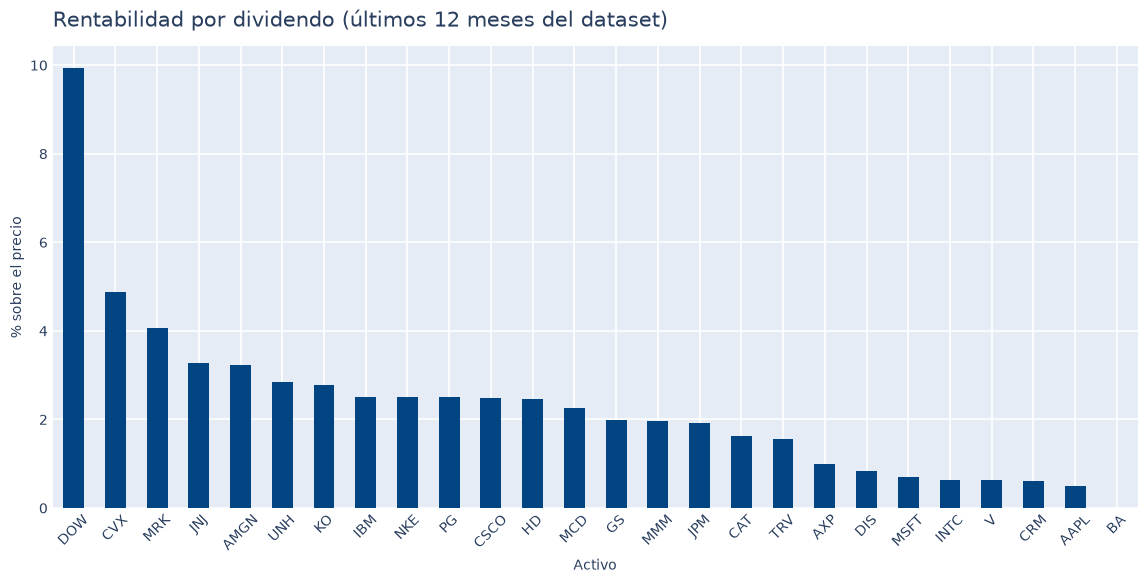

In [54]:
# Rentabilidad por dividendo de cada activo
(tabla_dividendos["Rentab. por dividendo"].sort_values(ascending=False) * 100).plot(kind="bar", figsize=(14, 6), color=paleta_bbva["azul_logotipo"])
plt.title("Rentabilidad por dividendo (últimos 12 meses del dataset)")
plt.xlabel("Activo")
plt.ylabel("% sobre el precio")
plt.xticks(rotation=45)
plt.show()

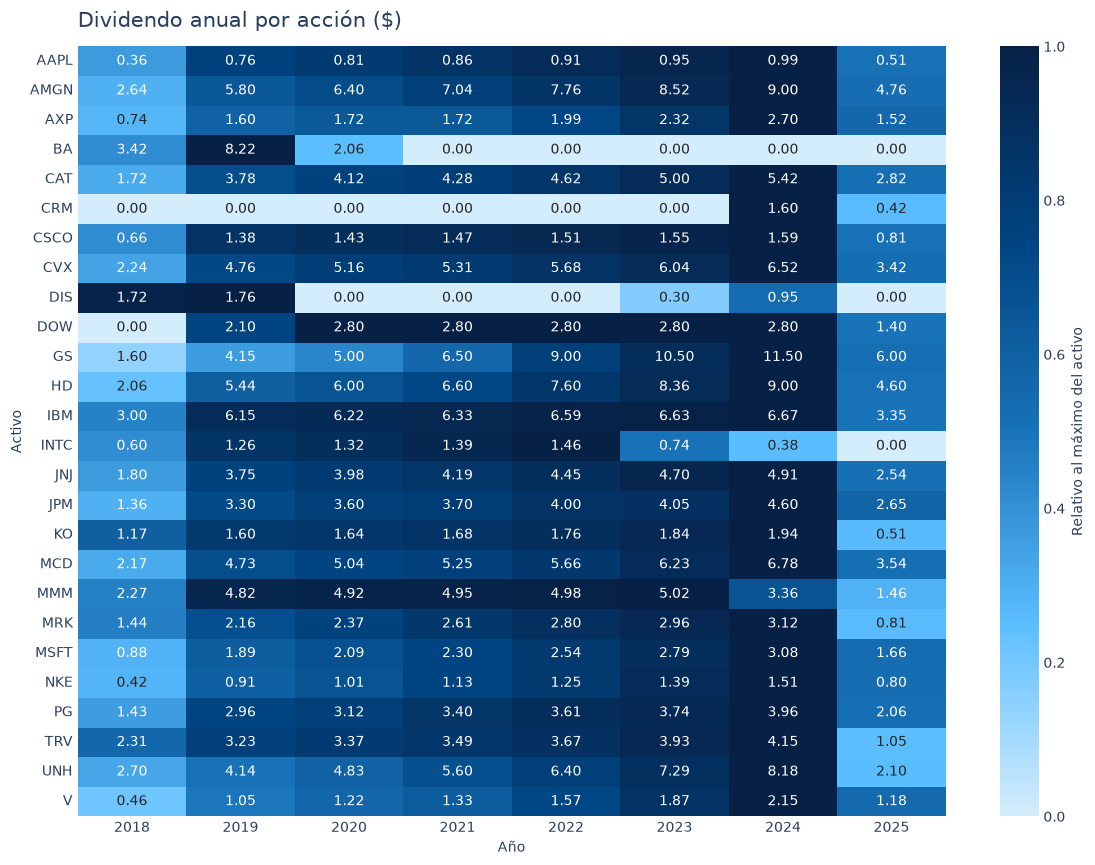

In [55]:
# Evolución del dividendo anual por acción: el color es relativo al máximo de cada activo
# (permite ver de un vistazo recortes, suspensiones y crecimiento); el número es el dividendo en $.
if dividendos:
    anios = list(range(inicio_periodo.year, fin_periodo.year + 1))
    dps_anual = (pd.DataFrame({t: s.groupby(s.index.year).sum() for t, s in dividendos.items()}).reindex(anios).T.reindex(tickers).fillna(0))
    relativo = dps_anual.div(dps_anual.max(axis=1).replace(0, np.nan), axis=0)

    plt.figure(figsize=(14, 10))
    sns.heatmap(relativo, annot=dps_anual, fmt=".2f", cmap=cmap_bbva, cbar_kws={"label": "Relativo al máximo del activo"})
    plt.title("Dividendo anual por acción ($)")
    plt.xlabel("Año")
    plt.ylabel("Activo")
    plt.show()
else:
    print("No se han obtenido dividendos.")

### Conclusiones: variables cualitativas

Los 26 activos son grandes empresas estadounidenses de sectores variados, con más peso de la tecnología (6 activos), los servicios financieros (5) y la salud (4). El consenso de los analistas es mayoritariamente positivo: 17 activos tienen recomendación de compra, 4 de compra fuerte (BA, DIS, MSFT y V) y solo 5 de mantener (AMGN, DOW, INTC, NKE y TRV).

El capital está muy concentrado en manos institucionales: las instituciones poseen entre el 63 % y el 93 % de cada empresa, mientras que los *insiders* apenas tienen participación, salvo en AXP (23 %), INTC (14 %) y KO (10 %), donde hay grandes accionistas de referencia. Las mismas cinco gestoras (BlackRock, State Street, Geode y las dos sociedades de Vanguard) están entre los diez mayores accionistas de los 26 activos, y BlackRock es el primer accionista en 24 de ellos (en AXP y KO lo es Berkshire Hathaway). Esta propiedad común, ligada en gran parte a los fondos indexados, ayuda a explicar por qué los activos se mueven juntos.

Solo cuatro activos hacen splits durante el periodo: AAPL (4:1 en agosto de 2020) y tres ajustes pequeños en MRK, IBM y MMM, ligados a la escisión de filiales (Organon, Kyndryl y Solventum). Ninguno coincide con las rentabilidades extremas detectadas, lo que confirma que los precios están ajustados por splits y que los saltos de junio de 2020 son errores del dataset y no eventos corporativos.

En cuanto a los dividendos, la rentabilidad por dividendo de los últimos doce meses va del 0 % de BA al 10,4 % de DOW, aunque una rentabilidad tan alta se debe sobre todo a la caída de su precio y no a un dividendo creciente, ya que DOW lo mantiene congelado en 2,80 $ por acción desde 2020. La mayoría de las empresas aumenta su dividendo cada año; destaca GS, que lo multiplica por 2,8 entre 2019 y 2024, y CRM empieza a pagarlo en 2024. En cambio, BA no paga dividendos desde 2020, DIS no los paga entre 2020 y 2022, INTC lo recorta en 2023 y deja de pagarlo en 2024, y MMM lo reduce tras la escisión de Solventum, señales de dificultades en esas empresas.

## 17. TABLA RESUMEN

Reunimos las principales métricas de rentabilidad y riesgo de cada activo, ordenados por ratio de Sharpe, para comparar los activos y justificar la elección.

In [56]:
#resumen
tabla_resumen = (tabla_final[["Rentabilidad anualizada", "Volatilidad anualizada", "Sharpe", "Drawdown máximo"]].sort_values("Sharpe", ascending=False))

tabla_resumen.style.format({
    "Rentabilidad anualizada": "{:.2%}", "Volatilidad anualizada": "{:.2%}", "Sharpe": "{:.2f}",
    "Drawdown máximo": "{:.2%}"}, na_rep="-")

,Rentabilidad anualizada,Volatilidad anualizada,Sharpe,Drawdown máximo
Activo,,,,
MSFT,25.53%,29.30%,0.87,-37.15%
AAPL,23.50%,31.67%,0.74,-38.57%
V,16.02%,24.88%,0.64,-35.97%
PG,14.81%,23.83%,0.62,-23.77%
GS,17.37%,30.11%,0.58,-44.79%
AXP,18.25%,34.30%,0.53,-49.64%
JPM,16.44%,31.93%,0.51,-43.63%
MCD,12.24%,24.24%,0.50,-36.90%
KO,10.67%,21.87%,0.49,-36.99%


### Conclusiones: tabla resumen y elección de los activos

La tabla resume la rentabilidad y el riesgo de los 26 activos ordenados por ratio de Sharpe y confirma lo visto en los apartados anteriores: MSFT, AAPL, V, GS, AXP, PG, JPM y CAT son los activos con mejor rentabilidad ajustada al riesgo, con un Sharpe superior a 0,4, mientras que INTC, DOW, BA y NKE ocupan las últimas posiciones, con un Sharpe negativo.

A partir de este análisis, los tres activos elegidos son Microsoft (MSFT), Goldman Sachs (GS) y Caterpillar (CAT). MSFT es el activo con mejor rentabilidad ajustada al riesgo del dataset: un 25,1 % de rentabilidad anualizada con un 28,9 % de volatilidad, un Sharpe de 0,87 y un drawdown máximo del −37,6 %, de los más contenidos entre los activos más rentables. GS aporta el sector financiero, con un 16,7 % de rentabilidad anualizada, un Sharpe de 0,56 y el dividendo que más crece entre las empresas que ya lo pagaban en 2019. CAT aporta el sector industrial, con un 13,6 % de rentabilidad anualizada y un Sharpe de 0,42, y más que duplica su valor en el periodo (+146 %).

Los tres activos pertenecen a sectores distintos, y MSFT tiene una correlación baja con GS (0,35) y con CAT (0,24), lo que mejora la diversificación de la cartera. Los principales riesgos de la selección son que GS y CAT están bastante correlacionadas entre sí (0,59), porque ambas dependen del ciclo económico, y que las dos sufrieron caídas importantes en marzo de 2020 (drawdown máximo del −45,1 % y del −40,8 %). Además, los tres comparten una base accionarial dominada por las mismas gestoras (BlackRock, Vanguard y State Street), lo que refuerza su exposición al riesgo de mercado.

## 18. GRÁFICOS Y TABLAS DE LOS ACTIVOS SELECCIONADOS

Gráficos y tablas que resumen el análisis anterior destacando los tres activos elegidos (MSFT, GS y CAT) frente al resto. Cada gráfico se guarda también como imagen PNG.

In [57]:
# Activos seleccionados y colores para destacarlos (el resto de activos en gris)
import os

seleccion = {"MSFT": paleta_bbva["azul_logotipo"], "GS": paleta_bbva["azul_celeste_aqua"], "CAT": paleta_bbva["azul_medio"]}
color_resto = "#B7C4D6"

# Letra algo más pequeña para los gráficos de este apartado
plt.rcParams.update({"font.size": 10, "axes.titlesize": 12, "axes.labelsize": 10, "legend.fontsize": 9})

carpeta_figuras = os.path.join("..", "DATOS", "GRAFICOS", "EDA")
os.makedirs(carpeta_figuras, exist_ok=True)

### 18.1 Evolución de los precios (base 100)

Mismo gráfico que el del apartado 4, pero con los tres activos seleccionados destacados. Cada activo se normaliza desde su primer precio disponible, así que DOW, que empieza a cotizar más tarde, también aparece.

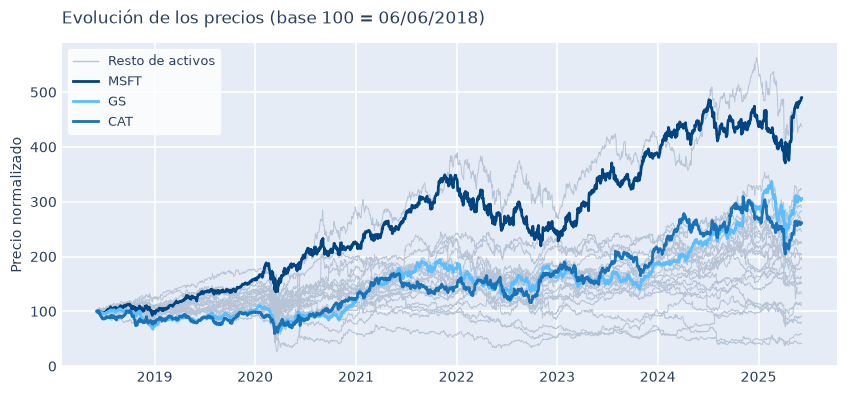

In [58]:
# Precios normalizados a base 100 con los activos seleccionados destacados
fig, ax = plt.subplots(figsize=(10, 4.2))

for activo in datos.columns:
    if activo not in seleccion:
        serie = datos[activo].dropna()
        ax.plot(serie.index, serie / serie.iloc[0] * 100, color=color_resto, linewidth=0.7)
ax.plot([], [], color=color_resto, linewidth=1, label="Resto de activos")

for activo, color in seleccion.items():
    serie = datos[activo].dropna()
    ax.plot(serie.index, serie / serie.iloc[0] * 100, color=color, linewidth=2, label=activo)

ax.set_title("Evolución de los precios (base 100 = 06/06/2018)")
ax.set_ylabel("Precio normalizado")
ax.legend(loc="upper left")
plt.savefig(os.path.join(carpeta_figuras, "precios_base100.png"), dpi=200, bbox_inches="tight")
plt.show()

### 18.2 Volatilidad a 30 días y drawdown de los activos seleccionados

A la izquierda, la volatilidad anualizada en ventanas de 30 días (apartado 7) de los tres activos, comparada con la mediana de los 26 activos. A la derecha, el drawdown de cada uno, medido como la caída desde el máximo alcanzado hasta ese día.

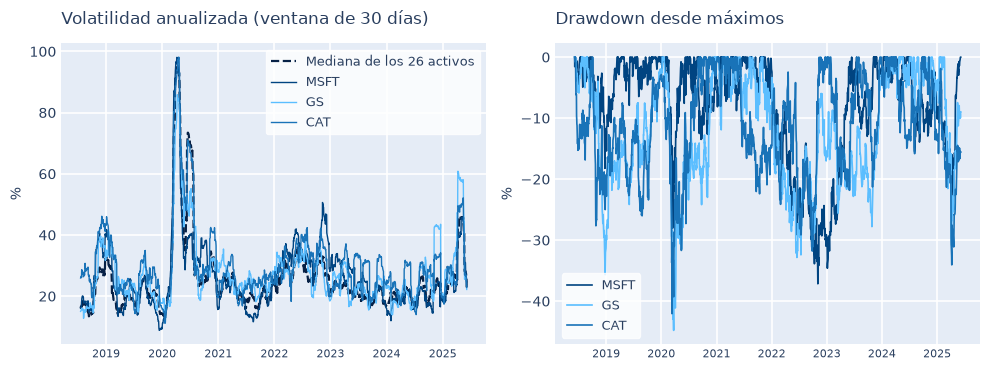

In [59]:
# Volatilidad a 30 días y drawdown desde máximos de los activos seleccionados
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))

axes[0].plot(volatilidad_30.index, volatilidad_30.median(axis=1) * 100, color=paleta_bbva["azul_oscuro_digital"],
             linewidth=1.6, linestyle="--", label="Mediana de los 26 activos")
for activo, color in seleccion.items():
    axes[0].plot(volatilidad_30.index, volatilidad_30[activo] * 100, color=color, linewidth=1, label=activo)
axes[0].set_title("Volatilidad anualizada (ventana de 30 días)")
axes[0].set_ylabel("%")
axes[0].legend(loc="upper right")

for activo, color in seleccion.items():
    serie = datos[activo]
    caida = (serie / serie.cummax() - 1) * 100
    axes[1].plot(caida.index, caida, color=color, linewidth=1.2, label=activo)
axes[1].set_title("Drawdown desde máximos")
axes[1].set_ylabel("%")
axes[1].legend(loc="lower left")

for ax in axes:
    ax.tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.savefig(os.path.join(carpeta_figuras, "volatilidad_drawdown.png"), dpi=200, bbox_inches="tight")
plt.show()

### 18.3 Riesgo-rentabilidad y ratio de Sharpe

A la izquierda, el gráfico riesgo-rentabilidad del apartado 12 y, a la derecha, el ratio de Sharpe del apartado 13 ordenado de mayor a menor, ambos con los activos seleccionados destacados.

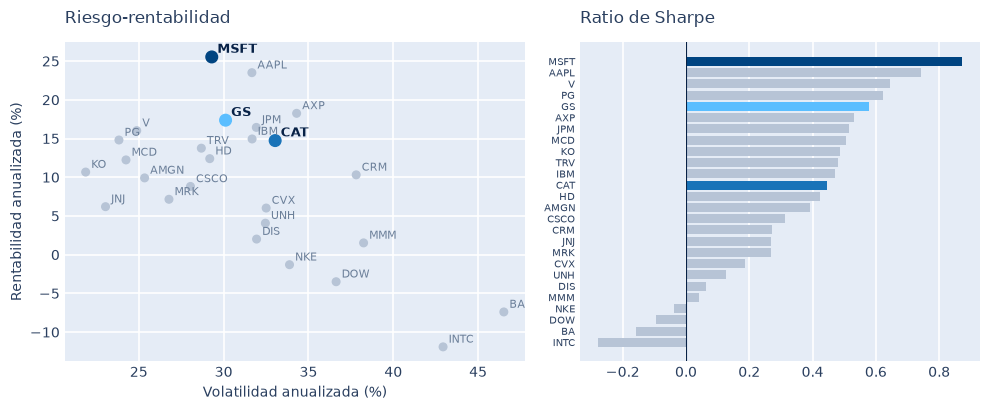

In [60]:
# Riesgo-rentabilidad y ranking del ratio de Sharpe
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})

vol = tabla_final["Volatilidad anualizada"] * 100
rent = tabla_final["Rentabilidad anualizada"] * 100
axes[0].scatter(vol, rent, c=[seleccion.get(a, color_resto) for a in vol.index],
                s=[70 if a in seleccion else 30 for a in vol.index], zorder=3)
for activo in vol.index:
    destacado = activo in seleccion
    axes[0].annotate(activo, (vol[activo], rent[activo]), textcoords="offset points", xytext=(4, 3),
                     fontsize=9 if destacado else 8, fontweight="bold" if destacado else "normal",
                     color=paleta_bbva["azul_oscuro_digital"] if destacado else "#6B7F99")
axes[0].set_title("Riesgo-rentabilidad")
axes[0].set_xlabel("Volatilidad anualizada (%)")
axes[0].set_ylabel("Rentabilidad anualizada (%)")

sharpe_ordenado = tabla_final["Sharpe"].sort_values()
axes[1].barh(sharpe_ordenado.index, sharpe_ordenado, color=[seleccion.get(a, color_resto) for a in sharpe_ordenado.index])
axes[1].axvline(0, color=paleta_bbva["azul_oscuro_digital"], linewidth=0.8)
axes[1].set_title("Ratio de Sharpe")
axes[1].tick_params(axis="y", labelsize=7)
axes[1].grid(axis="y", visible=False)

plt.tight_layout()
plt.savefig(os.path.join(carpeta_figuras, "riesgo_rentabilidad_sharpe.png"), dpi=200, bbox_inches="tight")
plt.show()

### 18.4 Rentabilidad y riesgo de los activos seleccionados

Métricas de la tabla final (apartado 11) para los tres activos seleccionados, comparadas con la mediana de los 26 activos.

In [61]:
# Tabla de rentabilidad y riesgo: activos seleccionados frente a la mediana de los 26 activos
metricas = ["Rentabilidad acumulada", "Rentabilidad anualizada", "Volatilidad anualizada", "Sharpe", "Sortino", "Drawdown máximo"]

tabla_seleccion = tabla_final.loc[list(seleccion), metricas].T
tabla_seleccion["Mediana 26 activos"] = tabla_final[metricas].median()

# Porcentajes con un decimal y ratios con dos decimales
tabla_seleccion_formateada = tabla_seleccion.astype(object)
for metrica in metricas:
    formato = "{:.2f}" if metrica in ["Sharpe", "Sortino"] else "{:.1%}"
    tabla_seleccion_formateada.loc[metrica] = tabla_seleccion.loc[metrica].map(formato.format)

tabla_seleccion_formateada

Activo,MSFT,GS,CAT,Mediana 26 activos
Rentabilidad acumulada,390.0%,206.2%,161.3%,100.8%
Rentabilidad anualizada,25.5%,17.4%,14.7%,10.5%
Volatilidad anualizada,29.3%,30.1%,33.0%,31.7%
Sharpe,0.87,0.58,0.45,0.41
Sortino,0.88,0.58,0.44,0.41
Drawdown máximo,-37.1%,-44.8%,-40.3%,-43.5%


### 18.5 Información cualitativa y dividendos de los activos seleccionados

Resumen de los datos del apartado 16 para los tres activos seleccionados: sector, recomendación de los analistas, accionistas, splits y dividendos.

In [62]:
# Tabla cualitativa de los activos seleccionados (datos del apartado 16)
filas = {}
for activo in seleccion:
    filas[activo] = {
        "Sector": perfil.loc[activo, "Sector"],
        "Recomendación analistas": perfil.loc[activo, "Recomendación analistas"],
        "Capital en manos de instituciones": f"{tabla_holders.loc[activo, 'Instituciones (%)']:.1%}",
        "Nº instituciones accionistas": f"{tabla_holders.loc[activo, 'Nº instituciones']:,.0f}",
        "Mayor accionista": f"{tabla_inst.loc[activo, 'Mayor holder']} ({tabla_inst.loc[activo, '% mayor holder']:.1%})",
        "Splits en el periodo": tabla_resumen_splits.set_index("Activo").loc[activo, "Tiene split"],
        "Rentab. por dividendo (12 meses)": f"{tabla_dividendos.loc[activo, 'Rentab. por dividendo']:.2%}",
        "Dividendo anual 2019 / 2024 ($)": f"{dps_anual.loc[activo, 2019]:.2f} / {dps_anual.loc[activo, 2024]:.2f}",
    }

tabla_cualitativa = pd.DataFrame(filas)
tabla_cualitativa

,MSFT,GS,CAT
Sector,Technology,Financial Services,Industrials
Recomendación analistas,strong_buy,buy,buy
Capital en manos de instituciones,75.7%,76.4%,73.7%
Nº instituciones accionistas,"8,201","3,973","4,839"
Mayor accionista,Blackrock Inc. (8.2%),Blackrock Inc. (8.3%),Blackrock Inc. (8.3%)
Splits en el periodo,No,No,No
Rentab. por dividendo (12 meses),0.69%,1.98%,1.62%
Dividendo anual 2019 / 2024 ($),1.89 / 3.08,4.15 / 11.50,3.78 / 5.42


### 18.6 Resumen numérico del análisis

Cálculos que resumen en una sola cifra algunos resultados de los apartados anteriores: precios iniciales, número de activos que duplican su valor, rango habitual de la volatilidad, fecha del peor drawdown de los activos seleccionados, número de activos con Sharpe superior a 0,4, diferencia entre Sortino y Sharpe, correlación media, saltos de junio de 2020 y crecimiento del dividendo.

In [63]:
# Periodo y precios iniciales
print(f"Sesiones: {len(datos)} ({pd.Timestamp(datos.index[0]).date()} a {pd.Timestamp(datos.index[-1]).date()})")
precio_inicial = datos.apply(lambda s: s.dropna().iloc[0]).sort_values()
print(f"Precio inicial más bajo: {precio_inicial.index[0]} ({precio_inicial.iloc[0]:.0f} $), {precio_inicial.index[1]} ({precio_inicial.iloc[1]:.0f} $), {precio_inicial.index[2]} ({precio_inicial.iloc[2]:.0f} $)")
print(f"Precio inicial más alto: {precio_inicial.index[-1]} ({precio_inicial.iloc[-1]:.0f} $)")

# Rentabilidad acumulada
acumulada = tabla_final["Rentabilidad acumulada"]
print(f"\nActivos que al menos duplican su valor: {(acumulada >= 1).sum()} de {len(acumulada)}")
print(f"Mediana de la rentabilidad acumulada: {acumulada.median():.1%}")

# Volatilidad a 30 días
mediana_vol = volatilidad_30.median()
print(f"\nVolatilidad a 30 días habitual (mediana de cada activo): de {mediana_vol.min():.1%} ({mediana_vol.idxmin()}) a {mediana_vol.max():.1%} ({mediana_vol.idxmax()})")
vol_media = volatilidad_30.mean(axis=1)
for anio in [2020, 2022, 2025]:
    pico = vol_media[str(anio)]
    print(f"Máximo de la volatilidad media de los 26 activos en {anio}: {pico.max():.1%} ({pd.Timestamp(pico.idxmax()).date()})")

# Fecha del peor drawdown de los activos seleccionados (caída desde el máximo alcanzado)
print()
for activo in seleccion:
    caida = datos[activo] / datos[activo].cummax() - 1
    print(f"Peor drawdown de {activo}: {caida.min():.1%} el {pd.Timestamp(caida.idxmin()).date()}")

# Sharpe y Sortino
print(f"\nActivos con Sharpe superior a 0,4: {(tabla_final['Sharpe'] > 0.4).sum()} ({', '.join(tabla_final.index[tabla_final['Sharpe'] > 0.4])})")
print(f"Diferencia máxima entre Sortino y Sharpe: {(tabla_final['Sortino'] - tabla_final['Sharpe']).abs().max():.3f}")

Sesiones: 1761 (2018-06-06 a 2025-06-06)
Precio inicial más bajo: KO (35 $), DOW (35 $), CSCO (36 $)
Precio inicial más alto: BA (358 $)

Activos que al menos duplican su valor: 13 de 26
Mediana de la rentabilidad acumulada: 100.8%

Volatilidad a 30 días habitual (mediana de cada activo): de 14.5% (KO) a 36.6% (INTC)
Máximo de la volatilidad media de los 26 activos en 2020: 100.4% (2020-04-08)
Máximo de la volatilidad media de los 26 activos en 2022: 35.6% (2022-05-31)
Máximo de la volatilidad media de los 26 activos en 2025: 50.2% (2025-05-15)

Peor drawdown de MSFT: -37.1% el 2022-11-03
Peor drawdown de GS: -44.8% el 2020-03-23
Peor drawdown de CAT: -42.0% el 2020-03-12

Activos con Sharpe superior a 0,4: 13 (AAPL, AXP, CAT, GS, HD, IBM, JPM, KO, MCD, MSFT, PG, TRV, V)
Diferencia máxima entre Sortino y Sharpe: 0.035


In [64]:
# Correlaciones: media, mínimo y máximo de todos los pares de activos
pares = correlation_mat.where(np.triu(np.ones(correlation_mat.shape, dtype=bool), k=1)).stack().dropna()
print(f"Correlación media: {pares.mean():.2f} | mínima: {pares.min():.2f} {pares.idxmin()} | máxima: {pares.max():.2f} {pares.idxmax()}")
print("Correlaciones entre los activos seleccionados:")
display(correlation_mat.loc[list(seleccion), list(seleccion)].round(2))

# Saltos de junio de 2020: activos con alguna variación diaria superior al 10 % en valor absoluto
junio_2020 = rent_sin_tz.loc["2020-06-01":"2020-06-30"]
afectados = junio_2020.columns[(junio_2020.abs() > 0.10).any()]
print(f"\nActivos con variaciones diarias superiores al 10 % en junio de 2020: {len(afectados)}")
print(", ".join(afectados))
cat_junio = junio_2020["CAT"][junio_2020["CAT"].abs() > 0.10]
print("Saltos de CAT en junio de 2020:", ", ".join(f"{pd.Timestamp(f).date()}: {v:+.1%}" for f, v in cat_junio.items()))

# Crecimiento del dividendo entre 2019 y 2024 (solo empresas que ya pagaban dividendo en 2019)
crecimiento = (dps_anual[2024] / dps_anual[2019])[dps_anual[2019] > 0].sort_values(ascending=False)
print("\nDividendo 2024 / dividendo 2019 (mayores crecimientos):")
print(crecimiento.head(5).round(2).to_string())

Correlación media: 0.37 | mínima: 0.05 ('CAT', 'PG') | máxima: 0.72 ('AXP', 'JPM')
Correlaciones entre los activos seleccionados:


Ticker,MSFT,GS,CAT
Ticker,,,
MSFT,1.00,0.35,0.23
GS,0.35,1.00,0.61
CAT,0.23,0.61,1.00



Activos con variaciones diarias superiores al 10 % en junio de 2020: 16
AXP, BA, CAT, CSCO, HD, IBM, INTC, JNJ, JPM, KO, MCD, MMM, MRK, PG, TRV, UNH
Saltos de CAT en junio de 2020: 2020-06-12: -11.6%, 2020-06-15: +12.4%

Dividendo 2024 / dividendo 2019 (mayores crecimientos):
GS     2.77
V      2.05
UNH    1.98
AXP    1.69
NKE    1.67
